In [ ]:
# Instal Package
!pip install yfinance xgboost optuna PyPortfolioOpt
!pip install rpy2 pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 18.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.6/67.6 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 11.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 160.8/160.8 kB 8.3 MB/s eta 0:00:00


# DATA
A. Seleksi Saham


# LOAD LIBRARY

In [ ]:
import pypfopt
pypfopt.__version__

'1.6.0'

In [ ]:
# Manipulasi data
import random
import numpy as np
import pandas as pd
# Pengambilan data
import yfinance as yf
# Visualisasi
import matplotlib.pyplot as plt
import seaborn as sns
# Statistik
from scipy import stats
from scipy.stats import jarque_bera, norm, skewnorm
from scipy.optimize import brentq
# Machine Learning
from xgboost import XGBRegressor
import optuna
# Evaluasi model
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)
# Time Series Cross Validation
from sklearn.model_selection import TimeSeriesSplit
# Black-Litterman / Portfolio
import pypfopt
from pypfopt import (
    risk_models,
    black_litterman,
    expected_returns,
    BlackLittermanModel,
    EfficientFrontier,
    objective_functions,
    plotting
)
# Setup Tampilan & Logging
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
optuna.logging.set_verbosity(optuna.logging.WARNING)
# Fungsi Pengunci Seed Global untuk Reproduksibilitas
SEED = 42
def set_global_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
set_global_seed(SEED)

# A. PREPARATION DATA

## Harga saham clean

In [ ]:
# Data update BEI  28 April 2025
# Periode efektif Konstituen: (6 Mei 2025 - 3 Feb 2026)
import yfinance as yf
tickers = [
    'ACES.JK', 'ADRO.JK', 'AKRA.JK', 'ANTM.JK', 'ASII.JK',
    'BBCA.JK', 'BBNI.JK', 'BBRI.JK', 'BMRI.JK', 'BNGA.JK',
    'HMSP.JK', 'INDF.JK', 'ITMG.JK', 'JPFA.JK', 'PGAS.JK',
    'PTBA.JK', 'SIDO.JK', 'TLKM.JK', 'UNTR.JK', 'UNVR.JK'
]
saham = [
    "ACES", "ADRO", "AKRA", "ANTM", "ASII", "BBCA", "BBNI",
    "BBRI", "BMRI", "BNGA", "HMSP", "INDF", "ITMG", "JPFA",
    "PGAS", "PTBA", "SIDO", "TLKM", "UNTR", "UNVR"
]
start, end = '2016-01-01', '2026-06-01'
data = yf.download(
    tickers,
    start=start,
    end=end,
    auto_adjust=False,
    progress=False
)
# Mengambil Adjusted Close Price
harga_saham_raw = (
    data["Adj Close"]
    .resample("W-FRI")
    .last()
)
harga_saham_raw.columns = saham
print("Ukuran data raw :", harga_saham_raw.shape)
display(harga_saham_raw.head())
display(harga_saham_raw.tail())

Ukuran data raw : (543, 20)


,ACES,ADRO,AKRA,ANTM,ASII,BBCA,BBNI,BBRI,BMRI,BNGA,HMSP,INDF,ITMG,JPFA,PGAS,PTBA,SIDO,TLKM,UNTR,UNVR
Date,,,,,,,,,,,,,,,,,,,,
2016-01-08,511.481812,112.890472,872.390991,224.631256,3516.837891,2045.554932,1643.259644,1243.424316,1335.624146,335.772369,2023.236450,3783.060059,1490.900757,411.240387,1391.840576,247.321121,152.918732,1841.577515,7683.965332,4893.677734
2016-01-15,542.376648,102.815063,778.001160,236.651672,3487.773682,2045.554932,1635.043457,1227.345337,1335.624146,332.997375,2092.778320,3816.390137,1406.632812,397.756989,1443.591919,256.513092,145.636887,1806.443848,7695.787598,4870.004883
2016-01-22,542.376648,117.928200,803.743591,231.392792,3429.644287,2045.554932,1643.259644,1208.586670,1350.024658,330.222382,1962.387085,3866.386719,1315.881836,448.319336,1356.431396,254.789566,145.636887,1865.000122,7719.429688,4815.894043
2016-01-29,549.242188,120.218071,840.927490,247.169571,3749.355957,2061.290283,1613.681030,1203.227295,1382.425171,335.772369,2249.247559,4133.034180,1247.171021,495.510834,1310.127808,255.651337,145.636887,1955.761475,8227.753906,4964.698730
2016-02-05,576.704346,146.551559,958.199829,256.936127,3865.615479,2112.429199,1733.639160,1318.458252,1490.426880,335.772369,2368.772949,4383.016602,1241.985352,508.994202,1321.022705,259.098358,148.549622,2049.450439,8180.468262,5492.281738


,ACES,ADRO,AKRA,ANTM,ASII,BBCA,BBNI,BBRI,BMRI,BNGA,HMSP,INDF,ITMG,JPFA,PGAS,PTBA,SIDO,TLKM,UNTR,UNVR
Date,,,,,,,,,,,,,,,,,,,,
2026-05-01,326.689667,2520.0,1477.162476,3485.013916,5687.806641,5827.413086,3720.0,2990.0,3971.258057,1670.0,692.551025,6466.304688,26650.0,2343.843262,1798.326416,2742.125244,500.0,2598.143311,29050.0,1429.900879
2026-05-08,346.765564,2490.0,1448.805542,3382.513428,5825.000000,6151.158203,3860.0,3260.0,4188.365234,1690.0,701.785034,6681.848145,24300.0,2410.000000,1733.438354,2732.570801,478.0,2736.834229,27400.0,1676.756836
2026-05-15,337.640167,2520.0,1405.341309,3261.376709,5750.000000,6076.447754,3870.0,3120.0,4136.128906,1675.0,683.317017,6538.152344,23950.0,2540.000000,1714.898926,2703.907471,444.0,2736.834229,26900.0,1662.783813
2026-05-22,317.564270,2350.0,1303.924927,2879.329590,5400.000000,5877.220215,3780.0,3050.0,4057.345703,1645.0,683.317017,6442.354980,23175.0,2570.000000,1687.089722,2598.808594,408.0,2699.849854,24050.0,1644.153198
2026-05-29,317.564270,2300.0,1192.849854,2702.283447,5000.000000,5677.992188,3700.0,2950.0,4017.954102,1615.0,695.000000,6633.949219,22100.0,2450.000000,1691.724609,2656.135254,384.0,2801.556641,22925.0,1592.918945


In [ ]:
# cek missing value
print("Missing Value Masing-masing Saham:")
display(harga_saham_raw.isna().sum())
print("\nTotal Missing Value:")
print(harga_saham_raw.isna().sum().sum())

Missing Value Masing-masing Saham:


,0
ACES,4
ADRO,4
AKRA,4
ANTM,4
ASII,4
BBCA,4
BBNI,4
BBRI,4
BMRI,4
BNGA,4



Total Missing Value:
80


In [ ]:
# Cleaning data saham
harga_saham_clean = harga_saham_raw.dropna().copy()
print("Ukuran harga :", harga_saham_clean.shape)
print("\nMissing Value Setelah Cleaning:")
print(harga_saham_clean.isna().sum().sum())
display(harga_saham_clean.head().round(2))
display(harga_saham_clean.tail().round(2))

Ukuran harga : (539, 20)

Missing Value Setelah Cleaning:
0


,ACES,ADRO,AKRA,ANTM,ASII,BBCA,BBNI,BBRI,BMRI,BNGA,HMSP,INDF,ITMG,JPFA,PGAS,PTBA,SIDO,TLKM,UNTR,UNVR
Date,,,,,,,,,,,,,,,,,,,,
2016-01-08,511.48,112.89,872.39,224.63,3516.84,2045.55,1643.26,1243.42,1335.62,335.77,2023.24,3783.06,1490.90,411.24,1391.84,247.32,152.92,1841.58,7683.97,4893.68
2016-01-15,542.38,102.82,778.00,236.65,3487.77,2045.55,1635.04,1227.35,1335.62,333.00,2092.78,3816.39,1406.63,397.76,1443.59,256.51,145.64,1806.44,7695.79,4870.00
2016-01-22,542.38,117.93,803.74,231.39,3429.64,2045.55,1643.26,1208.59,1350.02,330.22,1962.39,3866.39,1315.88,448.32,1356.43,254.79,145.64,1865.00,7719.43,4815.89
2016-01-29,549.24,120.22,840.93,247.17,3749.36,2061.29,1613.68,1203.23,1382.43,335.77,2249.25,4133.03,1247.17,495.51,1310.13,255.65,145.64,1955.76,8227.75,4964.70
2016-02-05,576.70,146.55,958.20,256.94,3865.62,2112.43,1733.64,1318.46,1490.43,335.77,2368.77,4383.02,1241.99,508.99,1321.02,259.10,148.55,2049.45,8180.47,5492.28


,ACES,ADRO,AKRA,ANTM,ASII,BBCA,BBNI,BBRI,BMRI,BNGA,HMSP,INDF,ITMG,JPFA,PGAS,PTBA,SIDO,TLKM,UNTR,UNVR
Date,,,,,,,,,,,,,,,,,,,,
2026-05-01,326.69,2520.0,1477.16,3485.01,5687.81,5827.41,3720.0,2990.0,3971.26,1670.0,692.55,6466.30,26650.0,2343.84,1798.33,2742.13,500.0,2598.14,29050.0,1429.90
2026-05-08,346.77,2490.0,1448.81,3382.51,5825.00,6151.16,3860.0,3260.0,4188.37,1690.0,701.79,6681.85,24300.0,2410.00,1733.44,2732.57,478.0,2736.83,27400.0,1676.76
2026-05-15,337.64,2520.0,1405.34,3261.38,5750.00,6076.45,3870.0,3120.0,4136.13,1675.0,683.32,6538.15,23950.0,2540.00,1714.90,2703.91,444.0,2736.83,26900.0,1662.78
2026-05-22,317.56,2350.0,1303.92,2879.33,5400.00,5877.22,3780.0,3050.0,4057.35,1645.0,683.32,6442.35,23175.0,2570.00,1687.09,2598.81,408.0,2699.85,24050.0,1644.15
2026-05-29,317.56,2300.0,1192.85,2702.28,5000.00,5677.99,3700.0,2950.0,4017.95,1615.0,695.00,6633.95,22100.0,2450.00,1691.72,2656.14,384.0,2801.56,22925.0,1592.92


## return_saham

In [ ]:
# Log return: diff(log(harga))
return_saham = np.log(
    harga_saham_clean / harga_saham_clean.shift(1)
).dropna()
print("Ukuran return :", return_saham.shape)
print("Missing Value :", return_saham.isna().sum().sum())
display(return_saham.head().round(4))
display(return_saham.tail().round(4))

Ukuran return : (538, 20)
Missing Value : 0


,ACES,ADRO,AKRA,ANTM,ASII,BBCA,BBNI,BBRI,BMRI,BNGA,HMSP,INDF,ITMG,JPFA,PGAS,PTBA,SIDO,TLKM,UNTR,UNVR
Date,,,,,,,,,,,,,,,,,,,,
2016-01-15,0.0586,-0.0935,-0.1145,0.0521,-0.0083,0.0000,-0.0050,-0.0130,0.0000,-0.0083,0.0338,0.0088,-0.0582,-0.0333,0.0365,0.0365,-0.0488,-0.0193,0.0015,-0.0048
2016-01-22,0.0000,0.1371,0.0326,-0.0225,-0.0168,0.0000,0.0050,-0.0154,0.0107,-0.0084,-0.0643,0.0130,-0.0667,0.1197,-0.0623,-0.0067,0.0000,0.0319,0.0031,-0.0112
2016-01-29,0.0126,0.0192,0.0452,0.0660,0.0891,0.0077,-0.0182,-0.0044,0.0237,0.0167,0.1364,0.0667,-0.0536,0.1001,-0.0347,0.0034,0.0000,0.0475,0.0638,0.0304
2016-02-05,0.0488,0.1981,0.1306,0.0388,0.0305,0.0245,0.0717,0.0915,0.0752,0.0000,0.0518,0.0587,-0.0042,0.0268,0.0083,0.0134,0.0198,0.0468,-0.0058,0.1010
2016-02-12,0.0293,-0.0645,-0.0584,0.0288,0.0260,-0.0112,0.0000,-0.0415,-0.0623,-0.0167,-0.0307,-0.0115,0.0042,0.0197,0.0184,-0.0236,0.0000,-0.0634,-0.0781,0.0122


,ACES,ADRO,AKRA,ANTM,ASII,BBCA,BBNI,BBRI,BMRI,BNGA,HMSP,INDF,ITMG,JPFA,PGAS,PTBA,SIDO,TLKM,UNTR,UNVR
Date,,,,,,,,,,,,,,,,,,,,
2026-05-01,-0.0856,0.0522,0.0654,-0.0796,-0.0569,-0.0336,-0.0134,-0.0264,-0.0247,-0.0194,0.0478,-0.0220,0.0492,-0.0587,0.0052,-0.0104,0.0040,0.0000,-0.0570,-0.0257
2026-05-08,0.0596,-0.0120,-0.0194,-0.0299,0.0238,0.0541,0.0369,0.0865,0.0532,0.0119,0.0132,0.0328,-0.0923,0.0278,-0.0367,-0.0035,-0.0450,0.0520,-0.0585,0.1593
2026-05-15,-0.0267,0.0120,-0.0305,-0.0365,-0.0130,-0.0122,0.0026,-0.0439,-0.0126,-0.0089,-0.0267,-0.0217,-0.0145,0.0525,-0.0108,-0.0105,-0.0738,0.0000,-0.0184,-0.0084
2026-05-22,-0.0613,-0.0698,-0.0749,-0.1246,-0.0628,-0.0333,-0.0235,-0.0227,-0.0192,-0.0181,0.0000,-0.0148,-0.0329,0.0117,-0.0163,-0.0396,-0.0846,-0.0136,-0.1120,-0.0113
2026-05-29,0.0000,-0.0215,-0.0890,-0.0635,-0.0770,-0.0345,-0.0214,-0.0333,-0.0098,-0.0184,0.0170,0.0293,-0.0475,-0.0478,0.0027,0.0218,-0.0606,0.0370,-0.0479,-0.0317


In [ ]:
print(f"Harga asli  : {harga_saham_raw.shape}")
print(f"Harga clean   : {harga_saham_clean.shape}")
print(f"Return saham  : {return_saham.shape}")

Harga asli  : (543, 20)
Harga clean   : (539, 20)
Return saham  : (538, 20)


## stat_desk

In [ ]:
stat_desk = return_saham.describe().T[["count", "min", "max", "mean", "50%", "std"]]
stat_desk.columns = ["N", "Min", "Max", "Mean", "Median", "Std Dev"]
stat_desk["Skewness"], stat_desk["Kurtosis"] = return_saham.skew(), return_saham.kurtosis()

stat_desk = stat_desk.reset_index().rename(columns={"index": "Saham"}).round(4)
display(stat_desk)

,Saham,N,Min,Max,Mean,Median,Std Dev,Skewness,Kurtosis
0,ACES,538.0,-0.1949,0.1873,-0.0009,0.0000,0.0514,0.0273,1.4227
1,ADRO,538.0,-0.3347,0.2843,0.0056,0.0028,0.0600,-0.1455,3.4490
2,AKRA,538.0,-0.2727,0.2527,0.0006,0.0000,0.0511,-0.0787,3.4146
3,ANTM,538.0,-0.2603,0.3359,0.0046,0.0000,0.0667,0.4691,3.1674
4,ASII,538.0,-0.2616,0.1836,0.0007,0.0000,0.0390,-0.2290,5.2319
5,BBCA,538.0,-0.1606,0.1516,0.0019,0.0010,0.0284,-0.0998,4.5559
6,BBNI,538.0,-0.3224,0.1398,0.0015,0.0022,0.0456,-0.9757,6.4983
7,BBRI,538.0,-0.2805,0.1735,0.0016,0.0000,0.0405,-0.7303,5.8279
8,BMRI,538.0,-0.3533,0.1648,0.0020,0.0034,0.0418,-1.1688,10.7739
9,BNGA,538.0,-0.1991,0.4055,0.0029,0.0000,0.0452,1.2894,14.4348


## uji_JB

In [ ]:
hasil_jb = []
for saham in return_saham.columns:
    jb_stat, jb_pvalue = jarque_bera(return_saham[saham])
    hasil_jb.append({
        "Saham": saham,
        "JB Statistic": jb_stat,
        "JB p-value": jb_pvalue,
        "Keputusan":
            "Normal"
            if jb_pvalue >= 0.05
            else
            "Tidak Normal"
    })
uji_JB = pd.DataFrame(hasil_jb).sort_values("JB p-value").round(10).reset_index(drop=True)
display(uji_JB)

,Saham,JB Statistic,JB p-value,Keputusan
0,BNGA,4725.704817,0.000000e+00,Tidak Normal
1,BMRI,2670.546187,0.000000e+00,Tidak Normal
2,SIDO,1315.613879,0.000000e+00,Tidak Normal
3,UNVR,1061.815726,0.000000e+00,Tidak Normal
4,BBNI,1010.807284,0.000000e+00,Tidak Normal
5,PGAS,846.498875,0.000000e+00,Tidak Normal
6,BBRI,791.981894,0.000000e+00,Tidak Normal
7,ASII,604.371874,0.000000e+00,Tidak Normal
8,JPFA,541.074296,0.000000e+00,Tidak Normal
9,HMSP,527.013757,0.000000e+00,Tidak Normal


**Interpretasi**
Signifikansi Alpha: 0.05

# B. SELECTION DATA

## harga_IHSG

In [ ]:
harga_IHSG = (
    yf.download(
        "^JKSE",
        start=start,
        end=end,
        auto_adjust=True,
        progress=False
    )["Close"]
    .resample("W-FRI")
    .last()
)
harga_IHSG = pd.DataFrame(harga_IHSG)
harga_IHSG.columns = ["IHSG"]
# Harga IHSG
print("Ukuran data IHSG :", harga_IHSG.shape)

Ukuran data IHSG : (543, 1)


In [ ]:
# Jumlah missing value
print("Missing Value")
display(harga_IHSG.isna().sum())
harga_IHSG = harga_IHSG.dropna()
print()
print("Ukuran data setelah cleaning :", harga_IHSG.shape)
display(harga_IHSG.head())
display(harga_IHSG.tail())

Missing Value


,0
IHSG,7



Ukuran data setelah cleaning : (536, 1)


,IHSG
Date,
2016-01-08,4546.111328
2016-01-15,4523.799805
2016-01-22,4456.570801
2016-01-29,4614.983398
2016-02-05,4798.758789


,IHSG
Date,
2026-05-01,6956.804199
2026-05-08,6969.395996
2026-05-15,6723.319824
2026-05-22,6162.044922
2026-05-29,6127.380859


## return_IHSG

In [ ]:
# Return IHSG
return_IHSG = (
    np.log(
        harga_IHSG /
        harga_IHSG.shift(1)
    )
    .dropna()
)
return_IHSG.columns = ['IHSG']
print("Ukuran return IHSG :", return_IHSG.shape)
display(return_IHSG.head())
display(return_IHSG.tail())

Ukuran return IHSG : (535, 1)


,IHSG
Date,
2016-01-15,-0.004920
2016-01-22,-0.014973
2016-01-29,0.034929
2016-02-05,0.039049
2016-02-12,-0.017776


,IHSG
Date,
2026-05-01,-0.024520
2026-05-08,0.001808
2026-05-15,-0.035947
2026-05-22,-0.087173
2026-05-29,-0.005641


## merge_return

In [ ]:
merge_return = (
    return_saham
    .join(
        return_IHSG,
        how="inner"
    )
)
print("Return Saham :", return_saham.shape)
print("Return IHSG  :", return_IHSG.shape)
print("Data Sinkron :", merge_return.shape)
display(merge_return)

Return Saham : (538, 20)
Return IHSG  : (535, 1)
Data Sinkron : (535, 21)


,ACES,ADRO,AKRA,ANTM,ASII,BBCA,BBNI,BBRI,BMRI,BNGA,...,INDF,ITMG,JPFA,PGAS,PTBA,SIDO,TLKM,UNTR,UNVR,IHSG
Date,,,,,,,,,,,,,,,,,,,,,
2016-01-15,0.058649,-0.093486,-0.114510,0.052129,-0.008299,0.000000,-0.005012,-0.013016,0.000000,-0.008299,...,0.008772,-0.058182,-0.033337,0.036507,0.036492,-0.048790,-0.019262,0.001537,-0.004849,-0.004920
2016-01-22,0.000000,0.137144,0.032552,-0.022473,-0.016807,0.000000,0.005012,-0.015402,0.010724,-0.008368,...,0.013015,-0.066692,0.119665,-0.062277,-0.006742,0.000000,0.031901,0.003067,-0.011173,-0.014973
2016-01-29,0.012579,0.019231,0.045225,0.065958,0.089128,0.007663,-0.018164,-0.004444,0.023716,0.016667,...,0.066691,-0.053629,0.100083,-0.034733,0.003377,0.000000,0.047519,0.063773,0.030431,0.034929
2016-02-05,0.048790,0.198070,0.130551,0.038753,0.030537,0.024506,0.071705,0.091456,0.075223,0.000000,...,0.058725,-0.004167,0.026847,0.008282,0.013393,0.019803,0.046792,-0.005764,0.100991,0.039049
2016-02-12,0.029328,-0.064539,-0.058388,0.028820,0.025975,-0.011236,0.000000,-0.041500,-0.062286,-0.016667,...,-0.011472,0.004167,0.019673,0.018387,-0.023557,0.000000,-0.063396,-0.078118,0.012240,-0.017776
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-05-01,-0.085614,0.052238,0.065383,-0.079631,-0.056926,-0.033617,-0.013351,-0.026404,-0.024748,-0.019447,...,-0.021979,0.049184,-0.058725,0.005168,-0.010399,0.004008,0.000000,-0.057002,-0.025725,-0.024520
2026-05-08,0.059638,-0.011976,-0.019384,-0.029853,0.023834,0.054067,0.036944,0.086454,0.053228,0.011905,...,0.032790,-0.092313,0.027835,-0.036750,-0.003490,-0.044997,0.052005,-0.058475,0.159256,0.001808
2026-05-15,-0.026668,0.011976,-0.030459,-0.036470,-0.012959,-0.012220,0.002587,-0.043894,-0.012550,-0.008915,...,-0.021740,-0.014508,0.052537,-0.010753,-0.010545,-0.073786,0.000000,-0.018417,-0.008368,-0.035947


## Var Kovar 20

In [ ]:
# Varians return saham
var_saham = merge_return.drop(columns="IHSG").var()
print(f"Varians saham : {var_saham}")

# Matriks kovarians antar saham
kov_saham = merge_return.drop(columns="IHSG").cov()
print(f"Kovarians saham : {kov_saham}")

# Varians return pasar
var_IHSG = merge_return["IHSG"].var()

# kovarians saham dan pasar
kov_pasar = merge_return.drop(columns="IHSG").apply(
    lambda x: x.cov(merge_return["IHSG"])
)
print(f"Kovarians saham dan pasar : {kov_pasar}")
print(f"Varians IHSG : {var_IHSG:.6f}")

Varians saham : ACES    0.002662
ADRO    0.003619
AKRA    0.002623
ANTM    0.004475
ASII    0.001527
BBCA    0.000813
BBNI    0.002095
BBRI    0.001646
BMRI    0.001760
BNGA    0.002053
HMSP    0.002111
INDF    0.001141
ITMG    0.003263
JPFA    0.003385
PGAS    0.003424
PTBA    0.002676
SIDO    0.001434
TLKM    0.001406
UNTR    0.002105
UNVR    0.002481
dtype: float64
Kovarians saham :           ACES      ADRO      AKRA      ANTM      ASII      BBCA      BBNI  \
ACES  0.002662  0.000467  0.000387  0.000498  0.000502  0.000429  0.000639   
ADRO  0.000467  0.003619  0.001088  0.001272  0.000481  0.000504  0.000813   
AKRA  0.000387  0.001088  0.002623  0.001038  0.000653  0.000503  0.000778   
ANTM  0.000498  0.001272  0.001038  0.004475  0.000769  0.000469  0.000895   
ASII  0.000502  0.000481  0.000653  0.000769  0.001527  0.000598  0.000879   
BBCA  0.000429  0.000504  0.000503  0.000469  0.000598  0.000813  0.000805   
BBNI  0.000639  0.000813  0.000778  0.000895  0.000879  0.000805 

In [ ]:
# Beta Saham
beta_saham = kov_pasar / var_IHSG
beta_saham = beta_saham.round(6)
display(beta_saham.to_frame("Beta"))

,Beta
ACES,0.759803
ADRO,1.126050
AKRA,1.016277
ANTM,1.435623
ASII,1.092819
BBCA,0.836945
BBNI,1.365065
BBRI,1.275290
BMRI,1.250753
BNGA,1.009023


## exp_capm

In [ ]:
saham = [
    "ACES","ADRO","AKRA","ANTM","ASII",
    "BBCA","BBNI","BBRI","BMRI","BNGA",
    "HMSP","INDF","ITMG","JPFA","PGAS",
    "PTBA","SIDO","TLKM","UNTR","UNVR"
]
# Return pasar rata-rata
Rm = merge_return["IHSG"].mean()
# Risk-free rate tahunan
rf_annual = 0.04925
# Risk-free rate mingguan (continuously compounded return)
rf = np.log(1 + rf_annual) / 52
# Excess return pasar (market risk premium)
ERm = Rm - rf
# Expected return CAPM
E_ri = rf + beta_saham * ERm
print(f"Mean Return Pasar : {Rm:.6f}")
print(f"Excess Return Pasar : {ERm:.6f}")
print(f"Risk Free Rate    : {rf:.6f}")
# Tampilan Data Frame
exp_capm = pd.DataFrame({
    "Saham": saham,
    "Beta": beta_saham.values,
    "rf"  : rf,
    "Rm"  : Rm,
    "E(ri)": E_ri.values
})
exp_capm["Beta"] = exp_capm["Beta"].round(6)
exp_capm["rf"] = exp_capm["rf"].round(6)
exp_capm["Rm"] = exp_capm["Rm"].round(6)
exp_capm["E(ri)"] = exp_capm["E(ri)"].round(6)
# urutkan hasil dari yang terbesar (positif)
exp_capm = exp_capm.sort_values(
    by="E(ri)",
    ascending=False
).reset_index(drop=True)
display(exp_capm)

Mean Return Pasar : 0.000558
Excess Return Pasar : -0.000367
Risk Free Rate    : 0.000925


,Saham,Beta,rf,Rm,E(ri)
0,SIDO,0.498710,0.000925,0.000558,0.000742
1,INDF,0.677685,0.000925,0.000558,0.000676
2,ACES,0.759803,0.000925,0.000558,0.000646
3,UNTR,0.787056,0.000925,0.000558,0.000636
4,ITMG,0.803996,0.000925,0.000558,0.000630
5,UNVR,0.830856,0.000925,0.000558,0.000620
6,BBCA,0.836945,0.000925,0.000558,0.000618
7,PTBA,0.848643,0.000925,0.000558,0.000613
8,HMSP,0.852650,0.000925,0.000558,0.000612
9,BNGA,1.009023,0.000925,0.000558,0.000555


## Goodness-of-Fit
menghitung Uji Kolmogorov-Smirnov (K-S Test), Log-Likelihood, AIC, dan BIC guna membandingkan kebaikan  (goodness-of-fit) Distribusi Normal vs Skew-Normal.


In [ ]:
def uji_goodness_of_fit_gof(return_df, daftar_20_saham):
    gof_results = []

    for stock in daftar_20_saham:
        r = return_df[stock].dropna().values
        n = len(r)

        # 1. FIT DISTRIBUSI NORMAL (Parameter: loc/μ, scale/σ -> k=2)
        mu_norm, sigma_norm = stats.norm.fit(r)

        # Uji Kolmogorov-Smirnov untuk Normal
        ks_stat_norm, p_val_norm = stats.kstest(r, 'norm', args=(mu_norm, sigma_norm))

        # Akaike & Bayesian Information Criterion (AIC & BIC) Normal
        loglik_norm = np.sum(stats.norm.logpdf(r, mu_norm, sigma_norm))
        k_norm = 2
        aic_norm = 2 * k_norm - 2 * loglik_norm
        bic_norm = k_norm * np.log(n) - 2 * loglik_norm

        # 2. FIT DISTRIBUSI SKEW-NORMAL (Parameter: shape/α, loc/μ, scale/σ -> k=3)
        alpha_sn, mu_sn, sigma_sn = stats.skewnorm.fit(r)

        # Uji Kolmogorov-Smirnov untuk Skew-Normal
        ks_stat_sn, p_val_sn = stats.kstest(r, 'skewnorm', args=(alpha_sn, mu_sn, sigma_sn))

        # Akaike & Bayesian Information Criterion (AIC & BIC) Skew-Normal
        loglik_sn = np.sum(stats.skewnorm.logpdf(r, alpha_sn, mu_sn, sigma_sn))
        k_sn = 3
        aic_sn = 2 * k_sn - 2 * loglik_sn
        bic_sn = k_sn * np.log(n) - 2 * loglik_sn

        # 3. KESIMPULAN FIT
        # Model dengan AIC/BIC lebih rendah dinyatakan lebih 'Fit'
        best_model = "Skew-Normal" if aic_sn < aic_norm else "Normal"

        gof_results.append({
            "Saham": stock,
            "KS-Stat (Normal)": ks_stat_norm,
            "p-value (Normal)": p_val_norm,
            "KS-Stat (Skew-Norm)": ks_stat_sn,
            "p-value (Skew-Norm)": p_val_sn,
            "AIC (Normal)": aic_norm,
            "AIC (Skew-Norm)": aic_sn,
            "Delta AIC (Norm - SN)": aic_norm - aic_sn, # Nilai positif menunjukkan SN lebih unggul
            "BIC (Normal)": bic_norm,
            "BIC (Skew-Norm)": bic_sn,
            "Model Terbaik": best_model
        })

    df_gof = pd.DataFrame(gof_results)
    return df_gof

# DATA FRAME HASIL
saham = [
    "ACES", "ADRO", "AKRA", "ANTM", "ASII",
    "BBCA", "BBNI", "BBRI", "BMRI", "BNGA",
    "HMSP", "INDF", "ITMG", "JPFA", "PGAS",
    "PTBA", "SIDO", "TLKM", "UNTR", "UNVR"
]
df_hasil_gof = uji_goodness_of_fit_gof(return_saham, saham)

print("\nTABEL EVALUASI GOODNESS-OF-FIT (NORMAL VS SKEW-NORMAL)")
display(df_hasil_gof.round(4))



TABEL EVALUASI GOODNESS-OF-FIT (NORMAL VS SKEW-NORMAL)


,Saham,KS-Stat (Normal),p-value (Normal),KS-Stat (Skew-Norm),p-value (Skew-Norm),AIC (Normal),AIC (Skew-Norm),Delta AIC (Norm - SN),BIC (Normal),BIC (Skew-Norm),Model Terbaik
0,ACES,0.0562,0.0643,0.0522,0.1026,-1662.9500,-1661.6695,-1.2805,-1654.3743,-1648.8060,Normal
1,ADRO,0.0545,0.0793,0.0509,0.1185,-1497.6039,-1497.7121,0.1083,-1489.0281,-1484.8485,Skew-Normal
2,AKRA,0.0563,0.0637,0.0540,0.0836,-1670.8953,-1670.5685,-0.3269,-1662.3196,-1657.7049,Normal
3,ANTM,0.0611,0.0345,0.0549,0.0748,-1383.4380,-1393.0359,9.5979,-1374.8623,-1380.1723,Skew-Normal
4,ASII,0.0677,0.0138,0.0695,0.0105,-1961.7211,-1962.5558,0.8348,-1953.1453,-1949.6923,Skew-Normal
5,BBCA,0.0760,0.0038,0.0738,0.0054,-2301.0318,-2301.3271,0.2953,-2292.4561,-2288.4635,Skew-Normal
6,BBNI,0.0816,0.0014,0.0756,0.0041,-1791.8088,-1811.5313,19.7225,-1783.2330,-1798.6677,Skew-Normal
7,BBRI,0.0768,0.0033,0.0664,0.0166,-1921.5924,-1934.7649,13.1726,-1913.0166,-1921.9013,Skew-Normal
8,BMRI,0.0711,0.0083,0.0641,0.0231,-1885.5344,-1904.6020,19.0676,-1876.9587,-1891.7384,Skew-Normal
9,BNGA,0.0970,0.0001,0.0900,0.0003,-1802.7228,-1823.1655,20.4427,-1794.1470,-1810.3019,Skew-Normal


## Saham Terpilih

In [ ]:
# 5 saham Terpilih
def seleksi_saham_capm_skewnorm(df_capm, df_gof, top_n=5):
  # 1. Gabungkan hasil CAPM dengan hasil Goodness-of-Fit berdasarkan nama Saham
  df_merged = pd.merge(df_capm, df_gof[['Saham', 'Model Terbaik', 'Delta AIC (Norm - SN)']], on='Saham')

  # 2. FILTERING: Ambil HANYA saham yang Model Terbaik-nya adalah 'Skew-Normal'
  df_filtered = df_merged[df_merged['Model Terbaik'] == 'Skew-Normal'].copy()

  # 3. SCORING / RANKING PERINGKAT CAPM:
  df_sorted = df_filtered.sort_values(
        by=['E(ri)', 'Beta'],
        ascending=[False, True]
    ).reset_index(drop=True)

  # 4. Ambil Top-5 Saham Terpilih
  saham_terpilih= seleksi_saham_capm_skewnorm(exp_capm, df_hasil_gof, top_n=5)
  display(saham_terpilih[['Saham', 'E(ri)', 'Beta', 'Model Terbaik', 'Delta AIC (Norm - SN)']])
  nama_terpilih = saham_terpilih['Saham'].tolist()
  return_terpilih = return_saham[nama_terpilih]
  display(return_terpilih.head())
  return nama_terpilih, return_terpilih
  display(return_terpilih.head())

## return_terpilih

In [ ]:
# Harga saham terpilih
harga_terpilih = harga_saham_clean[nama_terpilih]
# Return saham terpilih
return_terpilih = return_saham[nama_terpilih]
# Menyamakan index harga dengan return
harga_terpilih = harga_terpilih.loc[return_terpilih.index]
print("Ukuran Harga Saham  :", harga_terpilih.shape)
print("Ukuran Return Saham :", return_terpilih.shape)
display(harga_terpilih.head())
display(harga_terpilih.tail())

NameError: name 'nama_terpilih' is not defined

## Parameterisasi

> loc, scale, shape (μ,σ,α)

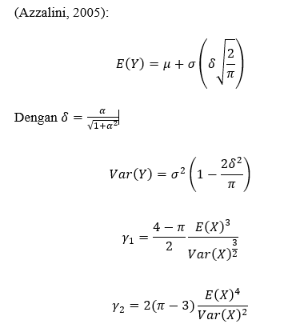







In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import skewnorm

# FITTING DISTRIBUSI SKEW-NORMAL DENGAN MLE
fit_sn, hasil_skewnorm = {}, {}

# Konfigurasi Grid Subplot
num_stocks = len(nama_terpilih)
cols = 3
rows = (num_stocks + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(18, 5 * rows))
axes = axes.flatten() if num_stocks > 1 else [axes]

# Loop setiap saham
for i, stock in enumerate(nama_terpilih):
    r = return_terpilih[stock].dropna()

    # 1. Estimasi Parameter Skew-Normal dengan MLE
    alpha_hat, mu_hat, sigma_hat = skewnorm.fit(r)

    # 2. Parameter Delta & Momen Standardized X ~ SN(0, 1, α)
    # δ = α / sqrt(1 + α²)
    delta_hat = alpha_hat / np.sqrt(1 + alpha_hat**2)

    # 3. Momen Teoritis untuk Y = μ + σ * X
    EX = np.sqrt(2 / np.pi) * delta_hat
    VarX = 1 - (2 * delta_hat**2 / np.pi)
    # E(Y) = μ + σδ sqrt(2/π)
    mean_theoretical = mu_hat + sigma_hat * EX
    # var(Y) = σ² (1 - 2δ²/π)
    variance_theoretical = (sigma_hat**2) * VarX
    # std.dev = sqrt(Var(Y))
    std_theoretical = np.sqrt(variance_theoretical)

    # 4. Skewness (γ1) & Excess Kurtosis (γ2) Teoritis
    gamma1 = ((4 - np.pi) / 2) * (EX**3) / (VarX**(3 / 2))
    gamma2 = 2 * (np.pi - 3) * (EX**4) / (VarX**2)

    # 5. Simpan Hasil Fitting
    hasil_skewnorm[stock] = {
        "Location (μ)": mu_hat,
        "Scale (σ)": sigma_hat,
        "Shape (α)": alpha_hat,
        "Delta_MLE": delta_hat,
        "Mean_Teoritis": mean_theoretical,
        "Variance_Teoritis": variance_theoretical,
        "Std_Teoritis": std_theoretical,
        "Skewness_Gamma1": gamma1,
        "Kurtosis_Gamma2": gamma2
    }

    # 6. Visualisasi Subplot
    ax = axes[i]

    ax.hist(r, bins=30, density=True, alpha=0.5, color='skyblue', edgecolor='black', label='Data Historis')
    x = np.linspace(r.min() - 0.05, r.max() + 0.05, 1000)

    # Kurva Skew-Normal dengan α_hat
    pdf_sn = skewnorm.pdf(x, alpha_hat, loc=mu_hat, scale=sigma_hat)

    # Kurva Normal (Skew-Normal saat α = 0)
    pdf_norm = skewnorm.pdf(x, 0, loc=mu_hat, scale=sigma_hat)

    ax.plot(x, pdf_norm, 'r--', linewidth=2, label='Fit Normal (α=0)')
    ax.plot(x, pdf_sn, 'g-', linewidth=2, label='Fit Skew-Normal')

    # Judul Subplot Format Gambar 1
    title_text = rf'Saham {stock}' + '\n' + rf'$\mu$={mu_hat:.4f}; $\sigma$={sigma_hat:.4f}; $\alpha$={alpha_hat:.4f};'
    ax.set_title(title_text, fontsize=11, fontweight='bold')
    ax.set_xlabel('Return')
    ax.set_ylabel('Density')
    ax.legend(loc='upper right')
    ax.grid(True, linestyle=':', alpha=0.6)

# Hapus subplot kosong jika ada
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Histogram dan Overlay Kurva Densitas (Normal vs Skew-Normal)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# Display Tabel Hasil Fitting MLE
df_hasil_skewnorm = pd.DataFrame(hasil_skewnorm).T
df_hasil_skewnorm.index.name = "Saham"

print("\nHASIL FITTING DAN PARAMETERISASI DISTRIBUSI SKEW-NORMAL")
display(df_hasil_skewnorm.round(5))

NameError: name 'nama_terpilih' is not defined

# C. PREDICTION XGBOOST

## Data Saham

In [ ]:
# Harga saham terpilih
harga_terpilih = harga_saham_clean[nama_terpilih]
# Return saham terpilih
return_terpilih = return_saham[nama_terpilih]
# Menyamakan index harga dengan return
harga_terpilih = harga_terpilih.loc[return_terpilih.index]
print("Ukuran Harga Saham  :", harga_terpilih.shape)
print("Ukuran Return Saham :", return_terpilih.shape)

**Pemilihan Window Terbaik**

In [ ]:
# Kandidat Rolling Window
window_list = [3, 5, 7, 9, 12]
print("Kandidat Window :", window_list)

In [ ]:
# Feature Engineering
def create_features(return_series, window):
    df = pd.DataFrame(index=return_series.index)
    # Variabel Target
    df["Target"] = return_series.shift(-1)
    # Variabel Predictor
    # X1 = Return minggu ke-t
    df["Return"] = return_series
    # X2 = Rolling Mean
    df["Rolling_Mean"] = (
        return_series
        .rolling(window)
        .mean()
    )
    # X3 = Rolling Standard Deviation
    df["Rolling_SD"] = (
        return_series
        .rolling(window)
        .std()
    )
    # X4 = Rolling Variance
    df["Rolling_Variance"] = (
        return_series
        .rolling(window)
        .var()
    )
    return df.dropna(subset=predictor_cols)

In [ ]:
# Evaluasi Semua Rolling Window
hasil_window = []
for window in window_list:
    print("="*60)
    print(f"WINDOW = {window}")
    for saham in return_terpilih.columns:
        # Feature Engineering
        df = create_features(
            return_terpilih[saham],
            window
        )
        # Split
        n = len(df)
        train_size = int(n * 0.80)
        train = df.iloc[:train_size]
        test = df.iloc[train_size:]
        X_train = train.drop(columns="Target")
        y_train = train["Target"]
        X_test = test.drop(columns="Target")
        y_test = test["Target"]
        # Model Default
        model = XGBRegressor(
            objective="reg:squarederror",
            random_state=42,
            seed=42,
            n_jobs=1,
            subsample=1.0,
            colsample_bytree=1.0
        )
        model.fit(
            X_train,
            y_train
        )
        pred = model.predict(X_test)
        # Evaluasi
        rmse = np.sqrt(
            mean_squared_error(
                y_test,
                pred
            )
        )
        mae = mean_absolute_error(
            y_test,
            pred
        )
        r2 = r2_score(
            y_test,
            pred
        )
        hasil_window.append([
            saham,
            window,
            rmse,
            mae,
            r2
        ])

In [ ]:
# Hasil Semua Window
hasil_window = pd.DataFrame(
    hasil_window,
    columns=[
        "Saham",
        "Window",
        "RMSE",
        "MAE",
        "R2"
    ]
)
display(hasil_window)

## Window terbaik

In [ ]:
ringkasan_window = (
    hasil_window
    .groupby("Window")[["RMSE", "MAE", "R2"]]
    .mean()
    .reset_index()
)

# Hitung Ranking Tiap Metrik
# RMSE semakin kecil
ringkasan_window["Rank_RMSE"] = (
    ringkasan_window["RMSE"]
    .rank(method="min", ascending=True)
)

# MAE semakin kecil
ringkasan_window["Rank_MAE"] = (
    ringkasan_window["MAE"]
    .rank(method="min", ascending=True)
)

# R² semakin besar
ringkasan_window["Rank_R2"] = (
    ringkasan_window["R2"]
    .rank(method="min", ascending=False)
)

# Total Score
ringkasan_window["Score"] = (
    ringkasan_window["Rank_RMSE"]
    + ringkasan_window["Rank_MAE"]
    + ringkasan_window["Rank_R2"]
)

# Urutkan dari Score Terbaik
ringkasan_window = (
    ringkasan_window
    .sort_values(
        by="Score",
        ascending=True
    )
    .reset_index(drop=True)
)

print("="*60)
print("RINGKASAN PEMILIHAN WINDOW TERBAIK")
print("="*60)

display(ringkasan_window)

In [ ]:
window_terbaik = ringkasan_window.iloc[0]
print(window_terbaik)
print("="*60)
print("WINDOW TERBAIK")
print("="*60)

display(window_terbaik)

**Interpretasi**
Window Terbaik = 9 atau 5

## Feature Engineering

In [ ]:
# Dataset Final (window=5)
dataset_final = {}
for stock in return_terpilih.columns:
  dataset_final[stock] = create_features(
      return_terpilih[stock],
      window=5 )
  print("="*60)
  print(stock)
  print(dataset_final[stock].head())

In [ ]:
dataset_final = {}
for stock in return_terpilih.columns:
  dataset_final[stock] = create_features(
      return_terpilih[stock],
      window=5 )
  print("="*60)
  display(stock)
  display(dataset_final[stock].head())
  display(dataset_final[stock].tail())

In [ ]:
# =====================================================
# FEATURE ENGINEERING
# =====================================================

dataset_final = {}

for stock in nama_terpilih:

    dataset_final[stock] = create_features(
        return_terpilih[stock],
        window=5
    )

    print("\n" + "=" * 70)
    print(f"DATASET HASIL FEATURE ENGINEERING - {stock}")
    print("=" * 70)

    print(
        f"Jumlah observasi : {dataset_final[stock].shape[0]}"
    )
    print(
        f"Jumlah variabel  : {dataset_final[stock].shape[1]}"
    )

    display(dataset_final[stock])

## Split Train-Test

Train = 80%
Test = 20%

TimeSeriesSplit
(5 Fold)


'SIDO', 'INDF', 'ACES', 'UNTR', 'ITMG'

In [ ]:
# Split Train-Test (Train = 80%, Test  = 20%)
train_test = {}
for saham, df in dataset_final.items():
    X = df[
        [
            "Return",
            "Rolling_Mean",
            "Rolling_SD",
            "Rolling_Variance"
        ]
    ]
    y = df["Target"]
    n = len(df)
    train_end = int(n * 0.80)
    train_test[saham] = {
        "X_train": X.iloc[:train_end],
        "X_test": X.iloc[train_end:],

        "y_train": y.iloc[:train_end],
        "y_test": y.iloc[train_end:]
    }

In [ ]:
# Ukuran Data Train-Test
for saham in train_test.keys():
    print("=" * 60)
    print(f"Saham : {saham}")
    print(f"X_train : {train_test[saham]['X_train'].shape}")
    print(f"X_test  : {train_test[saham]['X_test'].shape}")
    print("-" * 60)
    print(f"y_train : {train_test[saham]['y_train'].shape}")
    print(f"y_test  : {train_test[saham]['y_test'].shape}")
    print()

In [ ]:
display(train_test[nama_terpilih[0]]["X_train"])

**RINGKASAN**
Data Return 5 saham terpilih = 538 observasi

Feature Engineering = 1 var. Target + 4 var. prediktor

Rolling Window (window=5) = 533 observasi

Train 80% = 426
Test 20 % = 107

In [ ]:
tscv = TimeSeriesSplit(
    n_splits=5
)
# Pembagian TimeSeriesSplit
for saham in train_test.keys():
    print("="*70)
    print(f"SAHAM : {saham}")
    print("="*70)
    X_train = train_test[saham]["X_train"]
    for fold, (train_idx, valid_idx) in enumerate(
        tscv.split(X_train),
        start=1
    ):
        print(f"Fold {fold}")
        print(
            f"Train : {len(train_idx):3d} observasi "
            f"({train_idx[0]} - {train_idx[-1]})"
        )
        print(
            f"Valid : {len(valid_idx):3d} observasi "
            f"({valid_idx[0]} - {valid_idx[-1]})"
        )
        print("-"*60)


In [ ]:
# Ringkasan TimeSeriesSplit (5 Fold)
ringkasan_fold = []
X_train = train_test[nama_terpilih[0]]["X_train"]
for fold, (train_idx, valid_idx) in enumerate(
    tscv.split(X_train),
    start=1
):
    ringkasan_fold.append({
        "Fold": fold,
        "Train": len(train_idx),
        "Validation": len(valid_idx)
    })
ringkasan_fold = pd.DataFrame(ringkasan_fold)
print(ringkasan_fold)

## Hyperparameter Tuning (Optuna)


In [ ]:
import random
import numpy as np
import optuna
from xgboost import XGBRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error

# Matikan log Optuna yang berlebihan agar output bersih
optuna.logging.set_verbosity(optuna.logging.WARNING)

# =====================================================
# Hyperparameter Tuning
# Optuna + TimeSeriesSplit (5 Fold)
# Deterministic & Reproducible (random_state: 42)
# =====================================================

SEED = 42

def set_global_seed(seed=SEED):
    """Memastikan semua generator angka acak global terkunci."""
    random.seed(seed)
    np.random.seed(seed)

best_params = {}
tscv = TimeSeriesSplit(n_splits=5)

for saham in train_test.keys():
    # Kunci seed di setiap awal iterasi saham
    set_global_seed(SEED)

    print("=" * 60)
    print(f"Hyperparameter Tuning : {saham}")

    X_train = train_test[saham]["X_train"]
    y_train = train_test[saham]["y_train"]

    # Objective Function untuk Optuna
    def objective(trial):
        params = {
            "n_estimators": trial.suggest_int("n_estimators", 100, 300),
            "max_depth": trial.suggest_int("max_depth", 2, 5),
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.10),
            "subsample": trial.suggest_float("subsample", 0.70, 1.00),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.70, 1.00),
            "min_child_weight": trial.suggest_int("min_child_weight", 3, 10),
            "gamma": trial.suggest_float("gamma", 1.0, 10.0),
            "reg_alpha": trial.suggest_float("reg_alpha", 0.50, 5.00),
            "reg_lambda": trial.suggest_float("reg_lambda", 1.00, 10.00),
            "objective": "reg:squarederror",
            "random_state": SEED,
            "n_jobs": 1,
            "verbosity": 0,
        }

        rmse_fold = []

        # TimeSeries Cross Validation
        for train_idx, valid_idx in tscv.split(X_train):
            X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[valid_idx]
            y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[valid_idx]

            model = XGBRegressor(**params)
            model.fit(X_tr, y_tr)

            pred = model.predict(X_val)
            rmse = np.sqrt(mean_squared_error(y_val, pred))
            rmse_fold.append(rmse)

        return np.mean(rmse_fold)

    # -------------------------------------------------------------
    # Kunci Determinisme Optuna: Gunakan TPESampler dengan seed=42
    # -------------------------------------------------------------
    sampler = optuna.samplers.TPESampler(seed=SEED)

    study = optuna.create_study(
        direction="minimize",
        sampler=sampler
    )

    study.optimize(
        objective,
        n_trials=100,
        n_jobs=1  # Menjamin urutan eksekusi trial konsisten secara sekuensial
    )

    # Simpan parameter terbaik beserta random_state bawaannya
    best_opt_params = study.best_params
    best_opt_params["random_state"] = SEED
    best_params[saham] = best_opt_params

    print("Best RMSE :", round(study.best_value, 6))
    print("Best Params:", best_opt_params)

In [ ]:
display("Best RMSE :", round(study.best_value,6))

**TimeSeries Cross Validation** sudah dilakukan otomatis di setiap trial optuna

for train_idx, valid_idx in tscv.split(X_train):

TimeseriesSplit (k Fold)

Tidak cocok memakai K-Fold Cross Validation:
- Pada data time series urutan waktu tidak boleh diacak.
- menyebabkan data masa depan bisa masuk ke data training, sehingga terjadi data leakage.
- jadi, learning model -> tuning dengan validation -> diuji pada Test

Sebenarnya ada Cross Validation versi data time series namanya TImeSeriesSplit (evaluasi model lebih robust), tetapi pada penelitian saya tidak diperlukan. Kecuali fokus penelitian Perbandingan performa algoritma XGBoost, LSTM, Random Forest, SVR

## Best Hyperparameter

In [ ]:
# Best Hyperparameter
for saham in best_params.keys():

    print("="*60)
    print(saham)

    display(
        pd.DataFrame(
            best_params[saham].items(),
            columns=["Parameter","Value"]
        )
    )

In [ ]:
# =====================================================
# Ringkasan Best Hyperparameter
# =====================================================

ringkasan_hyperparameter = (
    pd.DataFrame.from_dict(
        best_params,
        orient="index"
    )
)

# Urutkan sesuai urutan saham terpilih
ringkasan_hyperparameter = (
    ringkasan_hyperparameter
    .loc[nama_terpilih]
)

# Jadikan parameter sebagai baris
ringkasan_hyperparameter = (
    ringkasan_hyperparameter
    .T
)

# Nama index
ringkasan_hyperparameter.index.name = "Parameter"

# Index menjadi kolom
ringkasan_hyperparameter = (
    ringkasan_hyperparameter
    .reset_index()
)

# Pembulatan angka
ringkasan_hyperparameter = (
    ringkasan_hyperparameter
    .round(2)
)

display(ringkasan_hyperparameter)

**INTERPRETASI**

*   Optuna (mencari kombinasi parameter terbaik secara otomatis).
*   Hasil tuning berbeda untuk setiap saham karena karakteristik return tiap saham berbeda.

*   Regularisasi yang cukup besar dipilih sehingga model lebih tahan terhadap overfitting.
*   Parameter terbaik tersebut digunakan sebagai dasar pelatihan model final XGBoost untuk menghasilkan prediksi return (views) yang kemudian menjadi input pada model Black–Litterman.

## Training Final XGBoost

In [ ]:
# =====================================================
# Training Final XGBoost
# Menggunakan seluruh data TRAIN (80%)
# =====================================================

from xgboost import XGBRegressor
final_models = {}
for saham in train_test.keys():
    # Data Train
    X_train = train_test[saham]["X_train"]
    y_train = train_test[saham]["y_train"]
    # Best Hyperparameter
    params = best_params[saham].copy()
    params.update({
        "objective": "reg:squarederror",
        "eval_metric": "rmse",
        "random_state": 42
    })
    # Final Model
    model = XGBRegressor(**params)
    model.fit(
        X_train,
        y_train
    )
    final_models[saham] = model
    print("Jumlah Data Train :", X_train.shape)

## Prediksi Test & Evaluasi Test

'SIDO', 'INDF', 'ACES', 'UNTR', 'ITMG'

In [ ]:
# ==========================================
# Evaluasi Test + Simpan Actual & Predicted
# ==========================================

def evaluasi_test(saham):
    X_test = train_test[saham]["X_test"]
    y_test = train_test[saham]["y_test"]
    # Prediksi data test
    pred = final_models[saham].predict(X_test)
    # Error Metrics
    mse = mean_squared_error(y_test, pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, pred)
    r2 = r2_score(y_test, pred)
    # Directional Accuracy
    direction_true = np.sign(y_test)
    direction_pred = np.sign(pred)
    DA = (
        direction_true == direction_pred
    ).mean()

    print("=" * 60)
    print(f"EVALUASI MODEL : {saham}")
    print("=" * 60)

    print(f"MSE  : {mse:.6f}")
    print(f"RMSE : {rmse:.6f}")
    print(f"MAE  : {mae:.6f}")
    print(f"R²   : {r2:.6f}")
    print(f"DA   : {DA:.2%}")

    return {

        "Saham": saham,

        # Error metrics
        "MSE": mse,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2,
        "DA": DA,

        # Data aktual dan prediksi
        "y_test": y_test.copy(),
        "y_pred": pd.Series(
            pred,
            index=y_test.index
        )

    }

In [ ]:
# ==========================================
# Evaluasi seluruh saham
# ==========================================

hasil_evaluasi = {}
hasil_metrik = []

for saham in train_test.keys():

    hasil = evaluasi_test(saham)

    hasil_evaluasi[saham] = hasil

    hasil_metrik.append({
        "Saham": hasil["Saham"],
        "MSE": hasil["MSE"],
        "RMSE": hasil["RMSE"],
        "MAE": hasil["MAE"],
        "R2": hasil["R2"],
        "DA": hasil["DA"]
    })

hasil_metrik = pd.DataFrame(hasil_metrik)

display(
    hasil_metrik.round(6)
)

Selain dievaluasi menggunakan RMSE, MAE, dan R
2
, penelitian ini juga menggunakan Directional Accuracy (DA) untuk mengukur kemampuan model dalam memprediksi arah pergerakan return saham. Hasil menunjukkan bahwa nilai DA bervariasi antar saham, yaitu antara 33,02% hingga 59,43%. Nilai DA tertinggi diperoleh pada saham UNTR sebesar 59,43%, sedangkan nilai terendah diperoleh pada saham ACES sebesar 33,02%. Hal ini menunjukkan bahwa kemampuan model dalam memprediksi arah return masih bervariasi pada masing-masing saham. Meskipun demikian, karena tujuan utama penelitian ini adalah menghasilkan estimasi return sebagai views pada model Black–Litterman, evaluasi utama tetap didasarkan pada besarnya kesalahan prediksi (RMSE dan MAE), sedangkan Directional Accuracy digunakan sebagai ukuran pelengkap untuk menilai kemampuan model dalam mengenali arah pergerakan return.

## Actual vs Prediksi

In [ ]:
# ==========================================
# Actual dan Predicted Return 5 Saham
# ==========================================

actual_test = pd.DataFrame({
    saham: hasil_evaluasi[saham]["y_test"]
    for saham in nama_terpilih
})

pred_test = pd.DataFrame({
    saham: hasil_evaluasi[saham]["y_pred"]
    for saham in nama_terpilih
})

print("Actual Test:")
display(actual_test.head())

print("Predicted Test:")
display(pred_test.head())

## Overfitting Check
Urutan:
1. Model dilatih
2. Model diuji pada data test
3. Nilai RMSE, MAE, dst diperoleh
4. Baru dicek (Train vs Test)
apakah performa train jauh lebih bagus dibanding test?
Apakah model terlalu hafal data training?

iya = overfitting

In [ ]:
# =====================================================
# Overfitting Check
# =====================================================

def overfitting_check(saham):

    # ==========================
    # Data Train
    # ==========================

    X_train = train_test[saham]["X_train"]
    y_train = train_test[saham]["y_train"]

    # ==========================
    # Data Test
    # ==========================

    X_test = train_test[saham]["X_test"]
    y_test = train_test[saham]["y_test"]

    # ==========================
    # Prediksi
    # ==========================

    pred_train = final_models[saham].predict(X_train)
    pred_test = final_models[saham].predict(X_test)

    # ==========================
    # Train Metrics
    # ==========================

    rmse_train = np.sqrt(
        mean_squared_error(
            y_train,
            pred_train
        )
    )

    mae_train = mean_absolute_error(
        y_train,
        pred_train
    )

    r2_train = r2_score(
        y_train,
        pred_train
    )

    # ==========================
    # Test Metrics
    # ==========================

    rmse_test = np.sqrt(
        mean_squared_error(
            y_test,
            pred_test
        )
    )

    mae_test = mean_absolute_error(
        y_test,
        pred_test
    )

    r2_test = r2_score(
        y_test,
        pred_test
    )

    # ==========================
    # Rasio Overfitting
    # ==========================

    rasio = rmse_test / rmse_train

    if rasio <= 1.20:
        status = "Baik"

    elif rasio <= 1.50:
        status = "Overfitting Ringan"

    else:
        status = "Overfitting"

    # ==========================
    # Output
    # ==========================

    print("="*60)
    print(f"OVERFITTING CHECK : {saham}")
    print("="*60)

    print(f"RMSE Train : {rmse_train:.6f}")
    print(f"RMSE Test  : {rmse_test:.6f}")

    print(f"MAE Train  : {mae_train:.6f}")
    print(f"MAE Test   : {mae_test:.6f}")

    print(f"R² Train   : {r2_train:.6f}")
    print(f"R² Test    : {r2_test:.6f}")

    print(f"Rasio      : {rasio:.3f}")
    print(f"Status     : {status}")

    return {

        "Saham": saham,

        "RMSE Train": rmse_train,
        "RMSE Test": rmse_test,

        "MAE Train": mae_train,
        "MAE Test": mae_test,

        "R2 Train": r2_train,
        "R2 Test": r2_test,

        "Rasio": rasio,

        "Status": status

    }

In [ ]:
# =====================================================
# Overfitting Check Semua Saham
# =====================================================

hasil_overfitting = []

for saham in nama_terpilih:

    hasil = overfitting_check(saham)

    hasil_overfitting.append(hasil)

In [ ]:
# =====================================================
# Ringkasan Overfitting
# =====================================================

tabel_overfitting = (
    pd.DataFrame(hasil_overfitting)
    .round(6)
)

print("="*60)
print("RINGKASAN OVERFITTING CHECK")
print("="*60)

display(tabel_overfitting)

Hasil pemeriksaan overfitting menunjukkan bahwa seluruh model XGBoost memiliki rasio RMSE data pengujian terhadap data pelatihan kurang dari 1,20 sehingga dikategorikan tidak mengalami overfitting. Selain itu, nilai MAE pada data pelatihan dan pengujian relatif berdekatan, yang menunjukkan bahwa model mampu melakukan generalisasi terhadap data baru. Meskipun nilai koefisien determinasi (R²) masih bernilai negatif, kondisi tersebut lebih disebabkan oleh karakteristik return saham mingguan yang sangat fluktuatif dan sulit diprediksi dibandingkan oleh terjadinya overfitting pada model. Dengan demikian, model XGBoost yang diperoleh dinilai cukup stabil untuk digunakan sebagai pembentuk views pada model Black–Litterman.

## Prediksi Return 1 bulan ke depan

In [ ]:
# =====================================================
# Prediksi Return t+1 (Views)
# =====================================================

predictions_next = {}

for saham in nama_terpilih:

    # ---------------------------------------
    # Ambil observasi terakhir
    # ---------------------------------------

    X_latest = dataset_final[saham][
        [
            "Return",
            "Rolling_Mean",
            "Rolling_SD",
            "Rolling_Variance"
        ]
    ].iloc[[-1]]

    # ---------------------------------------
    # Prediksi Return t+1
    # ---------------------------------------

    pred = final_models[saham].predict(
        X_latest
    )[0]

    predictions_next[saham] = pred

In [ ]:
# Cek tanggal terakhir data historis asli vs data fitur
for saham in nama_terpilih[:5]:
    print(f"--- Tanggal Terakhir {saham} ---")
    print("Data Aktual Asli :", harga_saham_clean[saham].index[-1].strftime('%Y-%m-%d'))
    print("Dataset Fitur Final:", dataset_final[saham].index[-1].strftime('%Y-%m-%d'))

In [ ]:
# =====================================================
# Solusi Perbaikan Tanggal Prediksi (t+1)
# =====================================================

features = ["Return", "Rolling_Mean", "Rolling_SD", "Rolling_Variance"]

# 1. Ambil Return Aktual Historis
df_aktual = return_saham[nama_terpilih].copy()

# 2. Hitung Prediksi t+1 untuk Setiap Saham
prediksi_t1 = {}
for saham in nama_terpilih:
    # Mengambil fitur dari observasi paling akhir di dataset_final
    X_latest = dataset_final[saham][features].iloc[[-1]]
    pred_val = final_models[saham].predict(X_latest)[0]
    prediksi_t1[saham] = pred_val

# 3. PERBAIKAN: Gunakan index df_aktual sebagai acuan tanggal terakhir
tanggal_terakhir_aktual = df_aktual.index[-1]  # 2026-05-29
tanggal_prediksi_t1 = tanggal_terakhir_aktual + pd.DateOffset(weeks=1) # 2026-06-05

# 4. Buat Baris Prediksi Baru
df_pred_baris = pd.DataFrame(prediksi_t1, index=[tanggal_prediksi_t1])

# 5. Gabungkan Return Historis + Baris Prediksi t+1
pred_xgb_wide = pd.concat([df_aktual, df_pred_baris])

# =====================================================
# Tampilkan Hasil Akhir
# =====================================================
print("=" * 60)
print("RETURN HISTORIS DAN PREDIKSI XGBOOST JUNI 2026")
print("=" * 60)
display(pred_xgb_wide.tail(6))
print(pred_xgb_wide.tail(6))

In [ ]:
# =====================================================
# Visualisasi Grafik Return Saham (Historis + Prediksi)
# =====================================================

# 1. Ambil data beberapa periode terakhir (misal 6 periode terakhir agar sama seperti gambar)
df_plot = pred_xgb_wide.tail(6)

# Setup figure
plt.figure(figsize=(12, 5), dpi=150)

# 2. Plot setiap saham dengan marker lingkaran ('o') dan ketebalan garis yang disesuaikan
for saham in df_plot.columns:
    plt.plot(
        df_plot.index.strftime('%Y-%m-%d'),  # Format tanggal sebagai string agar rapi di sumbu-x
        df_plot[saham],
        marker='o',
        linewidth=2,
        markersize=6,
        label=saham
    )

# 3. Tambahkan garis referensi horizontal di y=0 (garis putus-putus hitam)
plt.axhline(0, color='black', linestyle='--', linewidth=1)

# 4. Pengaturan Judul dan Label Sumbu
plt.title("GRAFIK RETURN SAHAM", fontsize=14, fontweight='bold', pad=25)
plt.ylabel("RETURN SAHAM", fontsize=11, fontweight='bold')

# 5. Pengaturan Legend di Tengah Atas (Horizontal)
plt.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, 1.08),
    ncol=len(df_plot.columns),
    frameon=False,
    fontsize=10
)

# 6. Pengaturan Grid & Style
plt.grid(True, linestyle=':', alpha=0.6)
plt.xticks(rotation=0, fontsize=9)
plt.yticks(fontsize=9)

plt.tight_layout()
plt.show()

## XGB

In [ ]:
# =====================================================
# Prediksi Return 1 minggu ke depan
# =====================================================
pred_xgb = (
    pd.DataFrame(
        predictions_next.items(),
        columns=[
            "Saham",
            "pred_xgb"
        ]
    )

)

print("="*60)
print("PREDIKSI RETURN t+1")
print("="*60)

print(pred_xgb)

## Visualisasi Prediksi


In [ ]:
# =====================================================
# ACTUAL VS PREDICTED RETURN - SUBPLOT
# =====================================================

import matplotlib.pyplot as plt
import math

# Jumlah saham
n_saham = len(nama_terpilih)

# Layout 2 baris x 3 kolom
n_cols = 3
n_rows = math.ceil(n_saham / n_cols)

# Membuat figure
fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(10, 6)
)

# Mengubah axes menjadi array 1 dimensi
axes = axes.flatten()

# Plot Actual vs Predicted setiap saham
for i, saham in enumerate(nama_terpilih):

    X_test = train_test[saham]["X_test"]
    y_test = train_test[saham]["y_test"]

    # Prediksi
    pred = final_models[saham].predict(X_test)

    # Actual Return
    axes[i].plot(
        y_test.values,
        label="Actual",
        linewidth=1.5
    )

    # Predicted Return
    axes[i].plot(
        pred,
        label="Predicted",
        linewidth=1.5
    )

    # Judul
    axes[i].set_title(
        f"{saham}",
        fontsize=11
    )

    # Label sumbu
    axes[i].set_xlabel(
        "Observasi",
        fontsize=9
    )

    axes[i].set_ylabel(
        "Return",
        fontsize=9
    )

    # Grid
    axes[i].grid(
        True,
        alpha=0.3
    )

    # Legend
    axes[i].legend(
        fontsize=8
    )

# Menghapus subplot yang tidak digunakan
for j in range(n_saham, len(axes)):
    fig.delaxes(axes[j])

# Judul utama
fig.suptitle(
    "Actual vs Predicted Return Model XGBoost",
    fontsize=14
)

# Mengatur tata letak
plt.tight_layout()

plt.show()

In [ ]:
# =====================================================
# SCATTER PLOT ACTUAL VS PREDICTED - SUBPLOT
# =====================================================

import matplotlib.pyplot as plt
import math

# Jumlah saham
n_saham = len(nama_terpilih)

# Layout 2 baris x 3 kolom
n_cols = 3
n_rows = math.ceil(n_saham / n_cols)

# Membuat figure
fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(10, 7)
)

# Mengubah axes menjadi array 1 dimensi
axes = axes.flatten()

# Scatter plot setiap saham
for i, saham in enumerate(nama_terpilih):

    X_test = train_test[saham]["X_test"]
    y_test = train_test[saham]["y_test"]

    # Prediksi
    pred = final_models[saham].predict(X_test)

    # Scatter Actual vs Predicted
    axes[i].scatter(
        y_test,
        pred,
        alpha=0.7
    )

    # Menentukan batas sumbu yang sama
    xmin = min(y_test.min(), pred.min())
    xmax = max(y_test.max(), pred.max())

    # Garis ideal y = x
    axes[i].plot(
        [xmin, xmax],
        [xmin, xmax],
        linestyle="--",
        linewidth=1
    )

    # Label sumbu
    axes[i].set_xlabel(
        "Actual Return",
        fontsize=9
    )

    axes[i].set_ylabel(
        "Predicted Return",
        fontsize=9
    )

    # Judul
    axes[i].set_title(
        f"{saham}",
        fontsize=11
    )

    # Grid
    axes[i].grid(
        True,
        alpha=0.3
    )

# Menghapus subplot yang tidak digunakan
for j in range(n_saham, len(axes)):
    fig.delaxes(axes[j])

# Judul utama
fig.suptitle(
    "Actual vs Predicted Return Model XGBoost",
    fontsize=14
)

# Mengatur tata letak
plt.tight_layout()

plt.show()

In [ ]:
# =====================================================
# HISTOGRAM RESIDUAL - SUBPLOT
# =====================================================

import matplotlib.pyplot as plt
import math

# Jumlah saham
n_saham = len(nama_terpilih)

# Menentukan jumlah baris dan kolom
n_cols = 3
n_rows = math.ceil(n_saham / n_cols)

# Membuat figure
fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(12, 6)
)

# Mengubah axes menjadi array 1 dimensi
axes = axes.flatten()

# Histogram residual setiap saham
for i, saham in enumerate(nama_terpilih):

    X_test = train_test[saham]["X_test"]
    y_test = train_test[saham]["y_test"]

    # Prediksi
    pred = final_models[saham].predict(X_test)

    # Residual
    residual = y_test - pred

    # Histogram
    axes[i].hist(
        residual,
        bins=20
    )

    axes[i].set_title(
        f"{saham}",
        fontsize=11
    )

    axes[i].set_xlabel(
        "Residual",
        fontsize=9
    )

    axes[i].set_ylabel(
        "Frekuensi",
        fontsize=9
    )

    axes[i].grid(
        True,
        alpha=0.3
    )

# Menghapus subplot yang tidak digunakan
for j in range(n_saham, len(axes)):
    fig.delaxes(axes[j])

# Judul utama
fig.suptitle(
    "Histogram Residual Model XGBoost",
    fontsize=14
)

# Mengatur jarak antar subplot
plt.tight_layout()

plt.show()

In [ ]:
# =====================================================
# RESIDUAL PLOT - SUBPLOT
# =====================================================

import matplotlib.pyplot as plt
import math

# Jumlah saham
n_saham = len(nama_terpilih)

# Layout 2 baris x 3 kolom
n_cols = 3
n_rows = math.ceil(n_saham / n_cols)

# Membuat figure
fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(10, 5)
)

# Mengubah axes menjadi array 1 dimensi
axes = axes.flatten()

# Residual plot setiap saham
for i, saham in enumerate(nama_terpilih):

    X_test = train_test[saham]["X_test"]
    y_test = train_test[saham]["y_test"]

    # Prediksi
    pred = final_models[saham].predict(X_test)

    # Residual
    residual = y_test - pred

    # Plot residual
    axes[i].plot(
        residual.values,
        linewidth=1.2
    )

    # Garis residual = 0
    axes[i].axhline(
        y=0,
        linestyle="--",
        linewidth=1
    )

    # Judul
    axes[i].set_title(
        f"{saham}",
        fontsize=11
    )
    # Label sumbu
    axes[i].set_xlabel(
        "Observasi",
        fontsize=9
    )
    axes[i].set_ylabel(
        "Residual",
        fontsize=9
    )
    axes[i].grid(
        True,
        alpha=0.3
    )

# Menghapus subplot yang tidak digunakan
for j in range(n_saham, len(axes)):
    fig.delaxes(axes[j])
fig.suptitle(
    "Residual Plot Model XGBoost",
    fontsize=14
)
plt.tight_layout()
plt.show()

# D. BL ORIGINAL
𝝨: risk_models.CovarianceShrinkage(harga_terpilih).ledoit_wolf()
δ: black_litterman.market_implied_risk_aversion(harga_IHSG)
q: absolute views
Ω: omega="idzorek"

## return_bl

In [ ]:
# Tentukan 5 saham terpilih untuk analisis Black-Litterman
nama_bl = ["SIDO", "INDF", "ACES", "UNTR", "ITMG"]
assets = nama_bl.copy()

# Filter return logaritma khusus 5 saham BL
return_bl = return_saham[assets].dropna().copy()

print("Daftar Saham BL:", assets)
print("Ukuran Data Return BL:", return_bl.shape)

## λ τ rf

In [ ]:
delta_BL = 2.5       # Parameter Risk Aversion (δ)
tau_BL = 0.05        # Tuning scalar prior uncertainty (τ)

# Risk-free rate tahunan (misal: BI-Rate / SBI 4.925%)
rf_annual = 0.04925
rf_weekly = np.log(1 + rf_annual) / 52  # Konversi ke log-return mingguan

print(f"Risk Aversion (δ) : {delta_BL}")
print(f"Tau (τ)           : {tau_BL}")
print(f"Rf Mingguan       : {rf_weekly:.6f}")

## cov_shringkage

In [ ]:
cov_shringkage = risk_models.CovarianceShrinkage(
   return_bl,
    returns_data=True,
    frequency=1  # Karena data sudah mingguan
).ledoit_wolf()

cov_norm = pd.DataFrame(cov_shringkage, index=assets, columns=assets)

print("\n--- Kovarians Ledoit-Wolf ---")
display(cov_norm.round(8))

## cov_norm

In [ ]:
#cov_norm = return_bl.cov()
#cov_norm = pd.DataFrame(cov_norm, index=assets, columns=assets)
#display(cov_norm.round(6))

## cek kovarians

In [ ]:
#selisih_cov = cov_shrinkage - cov_manual
#display(
#    selisih_cov.round(8)
#)
#perbandingan_cov = pd.DataFrame({
#    "Manual": cov_manual.values.flatten(),
#    "Ledoit_Wolf": cov_shrinkage.values.flatten(),
#    "Selisih": selisih_cov.values.flatten()
#})
#display(perbandingan_cov.round(8))

In [ ]:
plotting.plot_covariance(cov_norm, plot_correlation=True);

## Market Cap

In [ ]:
#mcaps = {}
#for t in tickers:
#    stock = yf.Ticker(t)
#    mcaps[t] = stock.info["marketCap"]
#mcaps

In [ ]:
nama_bl = ["SIDO", "INDF", "ACES", "UNTR", "ITMG"]
market_cap = {}
# Iterate over nama_bl to ensure market caps are fetched for all relevant stocks
for stock in nama_bl:
    ticker = stock + ".JK"
    try:
        info = yf.Ticker(ticker).info
        shares = info.get("sharesOutstanding")
        price = harga_saham_clean[stock].iloc[-1]

        if shares is not None:
            market_cap[stock] = shares * price
        else:
            print(f"{stock} : Shares Outstanding tidak tersedia")
    except Exception as e:
        print(stock, e)

market_cap = pd.Series(
    market_cap,
    name="Market_Cap"
)

market_cap = market_cap.reindex(nama_bl)

print("Market Capitalization:")
display(market_cap)

# Cek
assert len(market_cap) == 5
assert market_cap.index.tolist() == nama_bl
assert market_cap.notna().all()

print("Total Market Cap:", market_cap.sum())

## Prior : market cap

In [ ]:
market_prior = (
    black_litterman
    .market_implied_prior_returns(
        market_caps=market_cap,
        risk_aversion=delta_BL,
        cov_matrix=cov_norm,
        risk_free_rate=rf_weekly
    )
)

market_prior = pd.Series(
    market_prior,
    index=assets,
    name="Market_Prior"
)

print("\nMarket Implied Prior Return (Π):")

display(
    market_prior.to_frame().round(6)
)

In [ ]:
market_prior.plot.barh(figsize=(10,5));

## Absolute Views

In [ ]:
#viewdict = pred_xgb.copy()
#print("Matriks Views (q):")
#display(viewdict)

In [ ]:
# Absolute Views
viewdict = pred_xgb.set_index("Saham")["pred_xgb"].reindex(assets).astype(float)
viewdict.name = "View_XGB"
print("Matriks Views (q):")
display(viewdict.to_frame().round(6))

## Confidence

In [ ]:
mse_xgb = pd.Series(
    {
        saham: hasil_evaluasi[saham]["MSE"]
        for saham in nama_bl
    },
    name="MSE",
    dtype=float
)

mse_xgb = mse_xgb.reindex(nama_bl)
mse_series = mse_xgb.reindex(assets).astype(float)
rmse_series = np.sqrt(mse_series)
# CONFIDENCE
# Rumus Confidence: C_i = |Q_i| / (|Q_i| + RMSE_i)
confidence = viewdict.abs() / (viewdict.abs() + rmse_series)
confidence.name = "Confidence"

tabel_views = pd.concat([viewdict, mse_series.rename("MSE"), rmse_series.rename("RMSE"), confidence], axis=1)
print("\n--- Summary Views & Confidence Idzorek ---")
display(tabel_views.round(6))

In [ ]:
# ============================================================
# VALIDASI CONFIDENCE
# ============================================================

assert len(confidence) == 5
assert confidence.index.tolist() == nama_bl
assert ((confidence >= 0) & (confidence <= 1)).all()

print("Rentang confidence:")
print(
    f"Min = {confidence.min():.6f}"
)
print(
    f"Max = {confidence.max():.6f}"
)

## Expected Return BL NORMAL

In [ ]:
#bl_normal = BlackLittermanModel(
#    cov_matrix=S,
#    pi=market_prior,
#    absolute_views=pred_xgb,
#    view_confidences=confidence.values,
#    omega="idzorek",
#    tau=0.05,
#    risk_aversion=2.5 # Mengganti delta dengan nilai positif standar
#)

# Expected return BL Normal
#mu_BL_normal = bl_normal.bl_returns()

#print("Expected Return Black-Litterman Normal:")
#display(mu_BL_normal.round(8))

In [ ]:
# BLACK-LITTERMAN NORMAL
bl_normal = BlackLittermanModel(
    cov_matrix=cov_norm,                # kovarians               # kovarians
    pi=market_prior,                    # prior
    absolute_views=viewdict,            # views
    view_confidences=confidence.values, # confidence
    omega="idzorek",                    # matriks omega
    tau=0.05,                           # tau
)
# EXPECTED RETURN BLACK-LITTERMAN NORMAL
mu_BL_normal = bl_normal.bl_returns()

print("Expected Return Black-Litterman Normal:")
display(mu_BL_normal.round(6))

## Matriks Ω

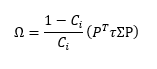

In [ ]:
# MATRIKS OMEGA - IDZOREK
omega_normal = pd.DataFrame(
    bl_normal.omega,
    index=assets,
    columns=assets
)
print("\nMatriks Omega Idzorek:")

display(
    omega_normal.round(6)
)
print("Dimensi Ω:", omega_normal.shape)

In [ ]:
#  P τΣ P'
P = bl_normal.P                          # matriks P
tau_covnorm = 0.05 * cov_norm.values     # tau * Sigma
omega_covnorm = P @ tau_covnorm @ P.T    # P * (tau * Sigma) * P^T

df_covnorm = pd.DataFrame(
    omega_covnorm,
    index=viewdict.keys(),
    columns=viewdict.keys()
)
print("Hasil Rumus P τΣ P':")
display(df_covnorm.round(6))

# Confidence
confidence = viewdict.abs() / (viewdict.abs() + rmse_series)
confidence.name = "Confidence"

# (1-Confidence)/Confidence * (P τΣ P')
omega_norm = (1 - confidence.values) / confidence.values
omega_manual_diag = np.diag(omega_covnorm) * omega_norm
omega_manual = np.diag(omega_manual_diag)

df_omega_manual = pd.DataFrame(
    omega_manual,
    index=viewdict.keys(),
    columns=viewdict.keys()
)
print("\nHasil Matriks Omega Manual :")
display(df_omega_manual.round(6))


In [ ]:
P_matrix = bl_normal.P
display(P_matrix)

In [ ]:
# ============================================================
# VALIDASI DIMENSI BLACK-LITTERMAN
# ============================================================

print("========== DIMENSI BLACK-LITTERMAN ==========")

print(f"Jumlah aset (N)      : {len(nama_bl)}")
print(f"Jumlah views (K)     : {len(viewdict)}")

print(f"\nΣ (Covariance)       : {cov_norm.shape}")
print(f"Π (Prior)            : {market_prior.shape}")
print(f"Q (Views)            : {viewdict.shape}")
print(f"Confidence           : {confidence.shape}")
print(f"Ω (Omega)            : {omega_normal.shape}")

print("\n==============================================")

# ============================================================
# ASSERTION
# ============================================================

N = len(nama_bl)
K = len(viewdict)

assert cov_norm.shape == (N, N)
assert market_prior.shape == (N,)
assert viewdict.shape == (K,)
assert confidence.shape == (K,)
assert omega_normal.shape == (K, K)

assert cov_norm.index.tolist() == nama_bl
assert cov_norm.columns.tolist() == nama_bl

assert market_prior.index.tolist() == nama_bl
assert viewdict.index.tolist() == nama_bl
assert confidence.index.tolist() == nama_bl

print("\n✓ Seluruh dimensi Black-Litterman konsisten.")

In [ ]:
# CEK MATRIKS P DAN VEKTOR Q
P_bl = pd.DataFrame(
    bl_normal.P,
    index=[f"View {i+1}" for i in range(K)],
    columns=nama_bl
)

Q_bl = pd.Series(
    bl_normal.Q.flatten(),
    index=[f"View {i+1}" for i in range(K)],
    name="Q"
)

print("Matriks P:")
display(P_bl)

print("\nVektor Q:")
display(Q_bl.round(5))

In [ ]:
# PERBANDINGAN PRIOR - VIEWS - POSTERIOR
hasil_BL_normal = pd.DataFrame({
    "Prior": market_prior,
    "Views_XGBoost": viewdict,
    "Posterior_BL_Normal": mu_BL_normal
})

display(
    hasil_BL_normal.round(5)
)

In [ ]:
print(hasil_BL_normal.round(5))

## Plot prior Views Posterior

In [ ]:
hasil_BL_normal.plot.bar(figsize=(12,8));

## Bobot BL Normal

In [ ]:
# ============================================================
# BOBOT RETURN-IMPLIED BLACK-LITTERMAN NORMAL
# w = (δΣ)^(-1) μ_BL
# ============================================================

delta_BL = 2.5

weights_BL_normal = bl_normal.bl_weights(
    risk_aversion=delta_BL
)

weights_BL_normal = pd.Series(
    weights_BL_normal,
    name="BL Normal"
)

print("Bobot BL Normal:")
display(
    weights_BL_normal.to_frame().round(5)
)

print(
    "Jumlah bobot:",
    weights_BL_normal.sum()
)

In [ ]:
pd.Series(weights_BL_normal).plot.pie(figsize=(10,10));

# E. BL SKEW NORMAL NEXT

## Teoritis vs Empiris

In [ ]:
# PERBANDINGAN MOMEN EMPIRIS DAN MOMEN TEORITIS
from scipy.stats import skew, kurtosis

# 1. Momen Teoritis Skew-Normal
moment_skew = df_hasil_skewnorm[["Mean_Teoritis", "Variance_Teoritis", "Std_Teoritis", "Skewness_Gamma1", "Kurtosis_Gamma2"]].copy()

# Interpretasi Momen
moment_skew["Interpretasi_Skewness"] = moment_skew["Skewness_Gamma1"].apply(lambda x: "Right Skew" if x > 0 else "Left Skew" if x < 0 else "Simetris")
moment_skew["Interpretasi_Kurtosis"] = moment_skew["Kurtosis_Gamma2"].apply(lambda x: "Leptokurtik (Heavy Tail)" if x > 0 else "Mesokurtik (Normal Tail)" if x == 0 else "Platikurtik (Light Tail)")
moment_skew.index.name = "Saham"

print("\nMOMEN TEORITIS DISTRIBUSI SKEW-NORMAL")
display(moment_skew.round(5))

In [ ]:
# 2. Statistik Empiris Data Return
statistik_empiris = {}
for stock in nama_terpilih:
    data = return_terpilih[stock].dropna()
    statistik_empiris[stock] = {
        "Mean_Data": data.mean(),
        "Variance_Data": data.var(),
        "Std_Data": data.std(),
        "Skewness_Data": skew(data, bias=False),
        "Kurtosis_Data": kurtosis(data, fisher=True, bias=False)
    }

statistik_empiris = pd.DataFrame(statistik_empiris).T
statistik_empiris.index.name = "Saham"

print("\nSTATISTIK EMPIRIS DATA RETURN")
display(statistik_empiris.round(5))

## BL SN

In [ ]:
# PARAMETERISASI BLACK-LITTERMAN SKEW-NORMAL
assets = nama_terpilih

# 1. Matriks Standar Deviasi (σ)
std_saham = np.sqrt(np.diag(cov_norm.values))
D_sigma = pd.DataFrame(np.diag(std_saham), index=assets, columns=assets)

print("=" * 70); print("MATRIKS STANDAR DEVIASI (σ)"); print("=" * 70)
display(D_sigma.round(5))

# 2. Matriks Korelasi (Σ̄)
D_inv = np.linalg.inv(D_sigma.values)
Sigma_bar_values = D_inv @ cov_norm.values @ D_inv
Sigma_bar = pd.DataFrame(Sigma_bar_values, index=assets, columns=assets)

print("=" * 70); print("MATRIKS KORELASI (Σ̄)"); print("=" * 70)
display(Sigma_bar.round(5))

## Parameter δ skew normal
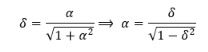

In [ ]:
# α = δ / sqrt(1 - δ²)
alpha = pd.Series(
    df_hasil_skewnorm.loc[:, "Shape (α)"],
    index=assets,
    name="Shape (α)"
)
print("Parameter shape alpha:")
display(
    alpha.to_frame().round(5)
)

# δ = α / sqrt(1 + α²)
delta_skew = (
    alpha
    /
    np.sqrt(1 + alpha**2)
)
delta_skew.name = "Delta_MLE"

print("Parameter delta skew-normal:")
display(
    delta_skew.to_frame().round(5)
)

In [ ]:
# 4. δ = E(X) / sqrt(2/π)
#delta_L = mean_return / np.sqrt(2 / np.pi)

#print("=" * 70); print("PARAMETER δ"); print("=" * 70)
#display(delta_L.to_frame(name="Delta").round(8))

# 5. α_L = δ / sqrt(1 - δ²)
#alpha_L = delta_L / np.sqrt(1 - delta_L**2)

#print("=" * 70); print("PARAMETER α_L"); print("=" * 70)
#display(alpha_L.to_frame(name="Alpha_L").round(8))

# 6. α = [α_L / sqrt(1+τ)]/sqrt[1 + τ/(1+τ) α_L'Σ̄α_L]
#tau = 0.05
#alpha_L_vector = alpha_L.values.reshape(-1, 1)
#quadratic_alpha_L = (alpha_L_vector.T @ Sigma_bar.values @ alpha_L_vector)[0, 0]

#numerator_alpha = alpha_L_vector / np.sqrt(1 + tau)
#denominator_alpha = np.sqrt(1 + (tau / (1 + tau)) * quadratic_alpha_L)

#alpha_values = numerator_alpha / denominator_alpha
#alpha = pd.Series(alpha_values.flatten(), index=assets, name="Alpha")

#print("=" * 70); print("PARAMETER α SKEW-NORMAL"); print("=" * 70)
#display(alpha.to_frame().round(8))

## Alpha Tilde
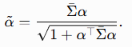

In [ ]:
# α̃ = Σ̄α / sqrt(1 + α'Σ̄α)
alpha_vector = alpha.values.reshape(-1, 1)
quadratic_alpha = (alpha_vector.T @ Sigma_bar.values @ alpha_vector)[0, 0]
denominator_alpha_tilde = np.sqrt(1 + quadratic_alpha)

alpha_tilde_values = (Sigma_bar.values @ alpha_vector) / denominator_alpha_tilde
alpha_tilde = pd.Series(alpha_tilde_values.flatten(), index=assets, name="Alpha_Tilde")

print("Parameter alpha_tilde:")
display(
    alpha_tilde.to_frame().round(5)
)

## Matriks Σ_x
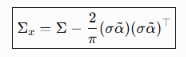

In [ ]:
# MATRIKS KOVARIANS TERKOREKSI (Σ_x)
# σ α_tilde
sigma_alpha_tilde = (
    D_sigma.values
    @ alpha_tilde.values.reshape(-1, 1)
)
sigma_alpha_tilde = pd.Series(
    sigma_alpha_tilde.flatten(),
    index=assets,
    name="Sigma_Alpha_Tilde"
)
print("sigma alpha_tilde:")
display(
    sigma_alpha_tilde.to_frame().round(5)
)

In [ ]:
# Koreksi Matriks Kovarians
# Rumus: Σ_x = Σ - (2/π) * (σ * α̃) * (σ * α̃)'
v = (
    sigma_alpha_tilde.values
    .reshape(-1, 1)
)

cov_x_values = (
    cov_norm.values
    -
    (2 / np.pi)
    *
    (v @ v.T)
)

cov_x = pd.DataFrame(
    cov_x_values,
    index=assets,
    columns=assets
)

# Memastikan simetris akibat numerical precision
cov_x = (
    cov_x + cov_x.T
) / 2

print("Matriks Kovarians Skew Normal (cov_x):")
display(
    cov_x.round(8)
)

print("Dimensi cov_x:", cov_x.shape)

## Prior, Q, Confidence

In [ ]:
assets = nama_terpilih.copy()
N = len(assets)

# 1. Prior market-implied
Pi = market_prior.copy()
Pi = Pi.reindex(assets)
Pi.name = "Prior"

# 2. Vektor Views
# mengubah dataframe ke vektor
if isinstance(pred_xgb, pd.DataFrame):
    Q = (
        pred_xgb
        .set_index("Saham")["pred_xgb"]
        .reindex(assets)
    )

else:

    Q = pred_xgb.copy()
    Q = Q.reindex(assets)

Q = pd.Series(
    Q.astype(float),
    index=assets,
    name="Views"
)

# 3. Confidence berdasarkan MSE XGBoost
mse_xgb = pd.Series(
    {
        saham: hasil_evaluasi[saham]["MSE"]
        for saham in assets
    },
    dtype=float,
    name="MSE"
)
mse_xgb = mse_xgb.reindex(assets)

# RMSE = sqrt(MSE)
rmse_xgb = np.sqrt(mse_xgb)
rmse_xgb.name = "RMSE"

confidence = (
    Q.abs()
    /
    (
        Q.abs() + rmse_xgb
    )
)
confidence = confidence.clip(0, 1)
confidence.name = "Confidence"

# Input BL
hasil_input_BL = pd.concat(
    [
        Pi,
        Q,
        mse_xgb,
        rmse_xgb,
        confidence
    ],
    axis=1
)
print("Input Black-Litterman:")
display(
    hasil_input_BL.round(8)
)

In [ ]:
print(cov_x)

In [ ]:
print(cov_norm)

## Matriks Ω

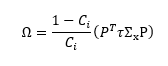

In [ ]:
#  P τΣ_x P'
P = bl_normal.P                          # matriks P
tau_covskew = 0.05 * cov_x.values        # tau * Sigma.x
omega_covskew = P @ tau_covskew @ P.T    # P * (tau * Sigma.x) * P^T

df_covskew = pd.DataFrame(
    omega_covskew,
    index=viewdict.keys(),
    columns=viewdict.keys()
)
print("Hasil Rumus P τΣ P':")
display(df_covskew.round(6))

# Confidence
confidence = viewdict.abs() / (viewdict.abs() + rmse_series)
confidence.name = "Confidence"

# (1-Confidence)/Confidence * (P τΣ_x P')
omega_skew = (1 - confidence.values) / confidence.values
omega_skew_diag = np.diag(omega_covskew) * omega_skew
omega_skew = np.diag(omega_skew_diag)

df_omega_skew = pd.DataFrame(
    omega_skew,
    index=viewdict.keys(),
    columns=viewdict.keys()
)
print("\nHasil Matriks Omega Manual :")
display(df_omega_skew.round(6))

In [ ]:
C = np.diag(
    confidence.reindex(assets).values
)
print("Matriks C")
display(pd.DataFrame(C, index=assets, columns=assets))

## Matriks P

In [ ]:
P = pd.DataFrame(
    np.eye(len(assets)),
    index=assets,
    columns=assets
)

print("Picking Matrix P:")
display(P)

## Komponen BL Skew

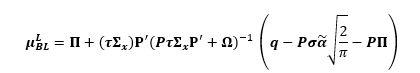

In [ ]:
# Π
Pi_vec = Pi.values if isinstance(Pi, (pd.Series, pd.DataFrame)) else Pi

# P, Q, Ω
P_mat = P.values if isinstance(P, pd.DataFrame) else P
Q_vec = Q.values if isinstance(Q, (pd.Series, pd.DataFrame)) else Q
omega_skew = np.diag(omega_skew_diag)

# τΣ_x
tau = 0.05
tau_covskew = tau * cov_x.values
# (τΣ_x)Pᵀ
covskew_P = tau_covskew @ P_mat.T
# (P(τΣ_x)Pᵀ+ Ω)(^-1)
middle_term = np.linalg.inv(P_mat @ tau_covskew @ P_mat.T + omega_skew)

# misal: (b = σ α *sqrt(2/π))
b_values = std_saham * alpha_tilde.values * np.sqrt(2 / np.pi)
b = pd.Series(b_values, index=assets, name="b")
display(b.to_frame().round(5))

# Q - P(b) - PΠ
hit_skew = Q_vec - (P_mat @ b) - (P_mat @ Pi_vec)
hit_skew_df = pd.DataFrame(hit_skew, columns=["Value"])
print("Komponen Views Skew Normal:")
display(hit_skew_df.round(5))

## Posterior BL Skew Normal
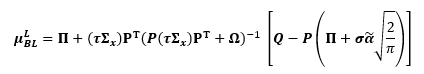

In [ ]:
# Posterior Black-Litterman Skew Normal
# Π + (τΣ_x)Pᵀ (P(τΣ_x)Pᵀ+ Ω)(^-1) [Q - P(b) - PΠ]
mu_BL_SN_values = Pi_vec + (covskew_P @ middle_term ) @ hit_skew

mu_BL_SN = pd.Series(
    mu_BL_SN_values.flatten(), index=assets, name="μ_BL_SN"
)
display(mu_BL_SN.round(5))

## Plot N vs SN

In [ ]:
hasil_final = pd.DataFrame({
    "Prior": Pi,
    "Views_XGBoost": Q,
    "Posterior_BL_Normal": mu_BL_normal,
    "Posterior_BL_Skew_Normal": mu_BL_SN
})

display(
    hasil_final.round(5)
)

In [ ]:
print(hasil_final.round(5))

In [ ]:
hasil_final.plot.bar(figsize=(12,8));

## Bobot N vs SN

In [ ]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize

# 1. Definisi Parameter dan Fungsi Objektif (Maksimasi Utility: w^T * mu - (delta/2) * w^T * Sigma * w)
def objective_utility(w, mu, cov, delta):
    portfolio_return = np.dot(w, mu)
    portfolio_variance = np.dot(w.T, np.dot(cov, w))
    # Minimasi negative utility (setara dengan maksimasi utility)
    return -(portfolio_return - (delta / 2) * portfolio_variance)

# 2. Inisialisasi Data
mu_sn = mu_BL_SN.values          # Expected Return BL Skew Normal
cov_sn = cov_x.values            # Matriks Kovarians BL Skew Normal
num_assets = len(assets)
delta_BL = 2.5                     # Koefisien Risk Aversion

# 3. Kendala dan Batasan (Constraints & Bounds)
bounds = tuple((0, 1) for _ in range(num_assets))              # w_i >= 0
constraints = ({'type': 'eq', 'fun': lambda w: np.sum(w) - 1}) # sum(w) = 1
initial_weights = np.array([1 / num_assets] * num_assets)      # Equal-weighted start

# 4. Optimasi Menggunakan scipy.optimize
result = minimize(
    objective_utility,
    initial_weights,
    args=(mu_sn, cov_sn, delta_BL),
    method='SLSQP',
    bounds=bounds,
    constraints=constraints
)

# 5. Format Hasil Bobot ke pd.Series
weights_BL_SN = pd.Series(result.x, index=assets, name="BL Skew Normal")

print("Bobot Portofolio BL Skew Normal (w >= 0, sum(w) = 1):")
print(weights_BL_SN.round(4))

## visualisasi Bobot

In [ ]:
# 1. Menggabungkan bobot BL Normal dan BL Skew Normal
df_weights = pd.DataFrame({
    "BL Normal": weights_BL_normal,
    "BL Skew Normal": weights_BL_SN
})

# 2. Menambahkan baris Total untuk verifikasi sum(w) = 1
df_weights.loc["TOTAL"] = df_weights.sum()

# 3. Menampilkan hasil dengan format persentase
print("=== PERBANDINGAN BOBOT PORTOFOLIO ===")
display(df_weights.round(4))

In [ ]:
# 4. Plot Visualisasi Perbandingan Bobot
df_weights.drop("TOTAL").plot(
    kind="bar",
    figsize=(10, 6),
    rot=0,
    title="Perbandingan Bobot Portofolio: BL Normal vs BL Skew Normal"
)

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Siapkan data tanpa baris TOTAL
df_plot = df_weights.drop("TOTAL", errors="ignore").copy()

# Rename kolom agar sesuai legenda gambar
df_plot.columns = ["Normal", "Skew Normal"]

# 2. Buat figure dan subplots
fig, ax = plt.subplots(figsize=(8, 6))

# Plot bar diagram
colors = ["#5B9BD5", "#ED7D31"]  # Warna biru & oranye khas Excel
df_plot.plot(
    kind="bar",
    ax=ax,
    color=colors,
    width=0.4,
    legend=False,  # Legenda disatukan ke dalam tabel di bawah
    zorder=3
)

# 3. Styling Grafik (Meniru gaya Excel)
ax.set_title("Perbandingan Bobot Black Litterman", fontsize=14, pad=15)
ax.set_xlabel("")
ax.set_ylabel("")

# Grid horizontal saja
ax.yaxis.grid(True, linestyle="-", color="#D3D3D3", alpha=0.7, zorder=0)
ax.xaxis.grid(False)

# Hilangkan garis spine/border atas, kanan, dan kiri
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_color("#D3D3D3")

# Sumbu Y dengan tanda koma (gaya penulisan Indonesia)
ticks_y = ax.get_yticks()
ax.set_yticklabels([f"{y:.1f}".replace('.', ',') for y in ticks_y], color="#595959")
ax.tick_params(axis="y", length=0)
ax.tick_params(axis="x", bottom=False, labelbottom=False) # Sembunyikan label X default karena diganti tabel

# 4. Membuat Tabel Data di Bawah Grafik
# Format angka menggunakan 6 desimal dan koma sebagai pemisah desimal
cell_text = []
for col in df_plot.columns:
    cell_text.append([f"{val:.6f}".replace('.', ',') for val in df_plot[col]])

table_data = plt.table(
    cellText=cell_text,
    rowLabels=df_plot.columns,
    colLabels=df_plot.index,
    rowColours=colors,
    cellLoc="center",
    rowLoc="left",
    loc="bottom",
    bbox=[0.0, -0.28, 1.0, 0.22] # [x, y, width, height]
)

# Formatting font dan ukuran tabel
table_data.auto_set_font_size(False)
table_data.set_fontsize(9)

# Menyesuaikan jarak bawah agar tabel tidak terpotong
plt.subplots_adjust(bottom=0.25)

plt.show()

## Return Risiko Porto

In [ ]:
import numpy as np
import pandas as pd

# ==============================================================================
# 1. PERHITUNGAN PORTOFOLIO BLACK-LITTERMAN NORMAL
# ==============================================================================
# Inisialisasi variabel BL Normal
w_normal = weights_BL_normal.values if isinstance(weights_BL_normal, pd.Series) else weights_BL_normal
mu_normal = mu_BL_normal.values if isinstance(mu_BL_normal, pd.Series) else mu_BL_normal
cov_normal = cov_norm.values if isinstance(cov_norm, pd.DataFrame) else cov_norm  # Matriks Kovarians BL Normal (S_bl)

# Expected Return: E(Rp) = w^T @ mu
er_bl_normal = np.dot(w_normal.T, mu_normal)

# Varians & Risiko Portofolio: sigma_p = sqrt(w^T @ Sigma @ w)
var_bl_normal = np.dot(w_normal.T, np.dot(cov_normal, w_normal))
risks_bl_normal = np.sqrt(var_bl_normal)


# ==============================================================================
# 2. PERHITUNGAN PORTOFOLIO BLACK-LITTERMAN SKEW-NORMAL
# ==============================================================================
# Inisialisasi variabel BL Skew-Normal
w_sn = weights_BL_SN.values if isinstance(weights_BL_SN, pd.Series) else weights_BL_SN
mu_sn = mu_BL_SN.values if isinstance(mu_BL_SN, pd.Series) else mu_BL_SN
cov_sn = cov_x.values if isinstance(cov_x, pd.DataFrame) else cov_x  # Matriks Kovarians BL Skew-Normal (Sigma_x)

# Expected Return: E(Rp) = w^T @ mu
er_bl_sn = np.dot(w_sn.T, mu_sn)

# Varians & Risiko Portofolio: sigma_p = sqrt(w^T @ Sigma_x @ w)
var_bl_sn = np.dot(w_sn.T, np.dot(cov_sn, w_sn))
risks_bl_sn = np.sqrt(var_bl_sn)


# ==============================================================================
# 3. PERBANDINGAN DAN TAMPILAN DATAFRAME
# ==============================================================================
hasil_evaluasi = pd.DataFrame({
    "BL Normal": [er_bl_normal, var_bl_normal, risks_bl_normal],
    "BL Skew Normal": [er_bl_sn, var_bl_sn, risks_bl_sn]
}, index=["Expected Return E(Rp)", "Varians Portofolio (sigma_p^2)", "Risiko Portofolio (sigma_p)"])

print("=== HASIL EVALUASI RETURN DAN RISIKO PORTOFOLIO ===")
display(hasil_evaluasi.round(5))

## Sharpe Ratio

In [ ]:
rf_weekly

In [ ]:
SR_norm = er_bl_normal/risks_bl_normal
print("Sharpe Ratio Normal :", SR_norm.round(4))

SR_skew=er_bl_sn/risks_bl_sn
print("Sharpe Ratio Skew Normal :", SR_skew.round(4))

In [ ]:
SR_norm = (er_bl_normal-rf_weekly)/risks_bl_normal
print("Sharpe Ratio Normal :", SR_norm.round(4))

SR_skew=(er_bl_sn-rf_weekly)/risks_bl_sn
print("Sharpe Ratio Skew Normal :", SR_skew.round(4))

## matriks Σ & matriks Ω

In [ ]:
print(cov_norm)

In [ ]:
print(cov_x)

In [ ]:
print(omega_manual)

In [ ]:
print(omega_skew)

## Studi Kasus

In [ ]:
# Portofolio BL berdistribusi Normal

# Return
ret_norm = 0.00289*100000000
print(ret_norm)
# Risiko
risk_norm = 0.02591*100000000
print(risk_norm)

In [ ]:
# Portofolio BL berdistribusi Skew Normal

# Return
ret_skew = 0.00322*100000000
print(ret_skew)
# Risiko
risk_skew = 0.02379*100000000
print(risk_skew)

In [ ]:
# Bobot Dana BL Normal
# SIDO
a_norm = 0.1578*100000000
print(a_norm)
# INDF
b_norm = 0.3167*100000000
print(b_norm)
# ACES
c_norm = 0.0635*100000000
print(c_norm)
# UNTR
d_norm = 0.3058*100000000
print(d_norm)
# ITMG
e_norm = 0.1562*100000000
print(e_norm)

In [ ]:
# Bobot Dana BL Skew Normal
# SIDO
a_skew = 0.2946*100000000
print(a_skew)

# INDF
b_skew = 0.2729*100000000
print(b_skew)

# ACES
c_skew = 0*100000000

# UNTR
d_skew = 0.4326*100000000
print(d_skew)
# ITMG
e_skew = 0*100000000

In [ ]:
total_norm = a_norm+b_norm+c_norm+d_norm+e_norm
print(total_norm)

total_skew = a_skew+b_skew+c_skew+d_skew+e_skew
print(total_skew)

In [ ]:
15780000+31670000+6350000+30580000+15620000

In [ ]:
# portofolio Normal
# SIDO
a_dana = a_norm/384
print(a_dana)

# INDF
b_dana = b_norm/6633
print(b_dana)

# ACES
c_dana = c_norm/317
print(c_dana)

# UNTR
d_dana = d_norm/22925
print(d_dana)

# ITMG
e_dana = e_norm/22100
print(e_dana)

In [ ]:
707/100

In [ ]:
# Portofolio skew Normal
# SIDO
skew_a = a_skew/384
print(skew_a)

# INDF
skew_b = b_skew/6633
print(skew_b)

# ACES
skew_c = c_skew/317
print(skew_c)

# UNTR
skew_d = d_skew/22925
print(skew_d)

# ITMG
skew_e = e_skew/22100
print(skew_e)

In [ ]:
1887/100

## Keuntungan aktual

In [ ]:
# harga aktual
tickers = ['SIDO.JK', 'INDF.JK', 'ACES.JK', 'UNTR.JK', 'ITMG.JK']
saham = [
    "SIDO", "INDF", "ACES", "UNTR","ITMG"
]
start, end = '2026-06-01', '2026-08-14'
harga5 = yf.download(tickers, start=start, end=end, auto_adjust=True, progress=False)["Close"].resample("W-FRI").last()
harga5.columns = saham
print("Ukuran data raw :", harga5.shape)
display(harga5.round(2))

In [ ]:
103228600-97913100

In [ ]:
# SIDO
sido = 358*76700
print(sido)

In [ ]:
# INDF
indf = 7450*4100
print(indf)

In [ ]:
# UNTR
untr = 25125*1800
print(untr)

In [ ]:
total = sido+indf+untr
print(total)

In [ ]:
384*41100

In [ ]:
6633*4800

In [ ]:
317*20000

In [ ]:
22925*1300

In [ ]:
22100*700

In [ ]:
15782400+31838400+6340000+29802500+15470000

In [ ]:
384*76700

In [ ]:
6633*4100

In [ ]:
22925*1800

In [ ]:
29452800+27195300+41265000

In [ ]:
360*76700

In [ ]:
6975*4100

In [ ]:
24575*1900

In [ ]:
27612000+28597500+46692500

In [ ]:
102902000-100205600

In [ ]:
100000000-97913100

#============================================

**Interpretasi** Estimasi parameter distribusi skew-normal mampu merepresentasikan karakteristik rata-rata, varians, dan arah kemencengan data return, tetapi belum sepenuhnya merepresentasikan karakteristik ekor distribusi yang ditunjukkan oleh nilai excess kurtosis empiris yang lebih tinggi daripada nilai teoritis. Karena distribusi skew normal tidak untuk mengontrol tail heaviness seperti skew-t


Alhamdulillah perbandingan hasilnya sama, jadi rumus parameterisasi dengan fit skewnormal bisa dianggap benar untuk digunakan perhitungan distribusi skew normal selanjutnya.

Hasil kurtosis berbeda karena distribusi skew normal tidak bisa menangkap heavy tail secara sempurna seperti skew-t

## ====BISMILLAH SELASAI===